# **STEP-1 Loading Baseline Summarization Model -> Mt5-large**

In [ ]:
pip install --upgrade transformers==4.44.2 datasets evaluate torch==2.4.0

In [8]:
import torch
import sys
import os
import gc
import random
import nltk
import numpy as np
import pandas as pd
import evaluate
import requests
from evaluate import load
from datasets import load_from_disk
from tqdm.auto import tqdm
from math import ceil
from huggingface_hub import whoami
from datasets import load_dataset, Dataset
from huggingface_hub import hf_hub_download
from transformers import (
    AutoTokenizer,
    AutoConfig,
    AutoModelForSeq2SeqLM,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainer,
    Seq2SeqTrainingArguments
)

In [9]:
# 1. PROFESSIONAL DEVICE DETECTION & SETUP
if torch.cuda.is_available():
    device = torch.device("cuda")
    # Tell PyTorch to be aggressive with GPU memory
    os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
    # Enable Mixed Precision for NVIDIA GPUs (Ultra Speed)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    print(f"🚀 SUCCESS: Connected to NVIDIA GPU: {torch.cuda.get_device_name(0)}")
    print(f"📊 Total VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("💻 SUCCESS: Connected to Apple Silicon GPU (MPS)")
else:
    device = torch.device("cpu")
    print("⚠️ WARNING: No GPU found. Running on CPU (Very Slow)")

# 2. THE "CLEAN SLATE" FUNCTION
def clear_memory():
    """Clears all ghost tensors from RAM and VRAM"""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
    elif torch.backends.mps.is_available():
        torch.mps.empty_cache()
    print("🧹 Memory cleared and ready for Ultra-Level training.")

clear_memory()

# 3. GLOBAL SEED FOR REPRODUCIBILITY (EMNLP Standard)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

🚀 SUCCESS: Connected to NVIDIA GPU: NVIDIA H100 80GB HBM3 MIG 3g.40gb
📊 Total VRAM: 42.28 GB
🧹 Memory cleared and ready for Ultra-Level training.


In [10]:
# Force PyTorch to clear the "Ghost Memory"
gc.collect()
torch.cuda.empty_cache()
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

print("✅ GPU Memory Flushed. Ready.")

✅ GPU Memory Flushed. Ready.


In [4]:
try:
    user = whoami()
    print(f"Logged in as: {user['name']}")
except:
    print("Not logged in. Run 'huggingface_hub.login()' first.")

Logged in as: Parshav14


In [5]:
LANGUAGES = ["english", "french", "spanish", "turkish", "swahili"]

for lang in LANGUAGES:
    print(f"\n📥 Downloading {lang.upper()}...")

    dataset = load_dataset(
        "csebuetnlp/xlsum",
        "default",
        data_dir=lang,
        revision="refs/convert/parquet"
    )

    dataset.save_to_disk(f"/workspace/xlsum_{lang}_data")

print("✅ All languages saved to disk.")


📥 Downloading ENGLISH...


Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Saving the dataset (0/2 shards):   0%|          | 0/306522 [00:00<?, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/11535 [00:00<?, ? examples/s]

... (21 outputs left out)


📥 Downloading SWAHILI...


Generating train split: 0 examples [00:00, ? examples/s]

Saving the dataset (0/1 shards):   0%|          | 0/987 [00:00<?, ? examples/s]

✅ All languages saved to disk.


# *1) Fine-Tuning on XL-Sum Multilingual Dataset (131,881 samples on 5 Lang.)*

In [ ]:
import os
import torch
import numpy as np
import nltk
import gc
from math import ceil
from datasets import load_from_disk, concatenate_datasets
from transformers import (
    AutoTokenizer, 
    AutoModelForSeq2SeqLM, 
    AutoConfig,
    Seq2SeqTrainer, 
    Seq2SeqTrainingArguments, 
    DataCollatorForSeq2Seq
)
from transformers.trainer_utils import get_last_checkpoint
import evaluate

# =====================================================
# 1. H100 SUPER-OPTIMIZATION & SETUP
# =====================================================
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.set_float32_matmul_precision("high")

gc.collect()
torch.cuda.empty_cache()

print(f"🚀 Using Device: {torch.cuda.get_device_name(0)}")

# =====================================================
# 2. INTELLIGENT DATA LOADING & BALANCING
# =====================================================
langs = ["english", "french", "spanish", "turkish", "swahili"]
train_sets = []
val_sets = []

# Cap big languages to this amount to prevent dominance
# This ensures Swahili (7k) is not ignored by English (300k)
MAX_SAMPLES = 50000 

print("\n📚 Loading and Balancing Multilingual Data...")

for lang in langs:
    path = f"/workspace/jasmeet/xlsum_{lang}_data"
    
    if not os.path.exists(path):
        print(f"⚠️ Warning: {path} not found. Skipping {lang}.")
        continue
    
    ds = load_from_disk(path)
    
    # --- SMART BALANCING ---
    train_subset = ds["train"]
    original_size = len(train_subset)
    
    if original_size > MAX_SAMPLES:
        # Downsample big languages
        train_subset = train_subset.shuffle(seed=42).select(range(MAX_SAMPLES))
        print(f"   - {lang.upper()}: Capped {original_size} -> {MAX_SAMPLES} samples")
    else:
        # Keep small languages full
        print(f"   - {lang.upper()}: Kept all {original_size} samples")
        
    # Validation: Keep it small (1k) for fast evaluation during training
    val_subset = ds["validation"]
    if len(val_subset) > 1000:
        val_subset = val_subset.shuffle(seed=42).select(range(1000))

    train_sets.append(train_subset)
    val_sets.append(val_subset)

# Merge everything
train_dataset = concatenate_datasets(train_sets).shuffle(seed=42)
val_dataset = concatenate_datasets(val_sets).shuffle(seed=42)

print(f"\n✅ FINAL BALANCED TRAIN SIZE: {len(train_dataset)}")
print(f"✅ FINAL VALIDATION SIZE: {len(val_dataset)}")

# =====================================================
# 3. LOAD BASE MODEL (ENGLISH VANILLA)
# =====================================================
# We start from your English-only model to adapt it.
# We do NOT use consistency model yet.
BASE_MODEL_PATH = "/workspace/jasmeet/mt5_project/final_model"

if not os.path.exists(BASE_MODEL_PATH):
    raise ValueError(f"CRITICAL ERROR: Could not find model at {BASE_MODEL_PATH}")

print(f"\n📥 Loading Base English Model from: {BASE_MODEL_PATH}")

config = AutoConfig.from_pretrained(BASE_MODEL_PATH)
config.tie_word_embeddings = False 

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_PATH)
model = AutoModelForSeq2SeqLM.from_pretrained(
    BASE_MODEL_PATH,
    config=config
).to(device)

model.gradient_checkpointing_enable()
model.config.use_cache = False

# =====================================================
# 4. PREPROCESSING
# =====================================================
MAX_INPUT = 640
MAX_TARGET = 160

def preprocess(batch):
    inputs = tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_INPUT
    )
    labels = tokenizer(
        text_target=batch["summary"],
        truncation=True,
        max_length=MAX_TARGET
    )
    inputs["labels"] = labels["input_ids"]
    return inputs

print("🔄 Tokenizing dataset...")

tokenized_train = train_dataset.map(
    preprocess,
    batched=True,
    remove_columns=train_dataset.column_names,
    num_proc=8
)

tokenized_val = val_dataset.map(
    preprocess,
    batched=True,
    remove_columns=val_dataset.column_names,
    num_proc=8
)

# =====================================================
# 5. ROBUST METRICS (CRASH-PROOF)
# =====================================================
nltk.download("punkt", quiet=True)
rouge = evaluate.load("rouge")

def compute_metrics(eval_pred):
    predictions, labels = eval_pred

    # Safety: Handle tuple outputs
    if isinstance(predictions, tuple):
        predictions = predictions[0]

    predictions = np.asarray(predictions).astype(np.int64)
    labels = np.asarray(labels).astype(np.int64)

    # Replace -100 with pad token
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)

    # Safety: Clip invalid tokens
    vocab_size = tokenizer.vocab_size
    predictions = np.clip(predictions, 0, vocab_size - 1)

    decoded_preds = tokenizer.batch_decode(predictions, skip_special_tokens=True)
    decoded_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    # ROUGE expects newlines
    decoded_preds = ["\n".join(nltk.sent_tokenize(p.strip())) for p in decoded_preds]
    decoded_labels = ["\n".join(nltk.sent_tokenize(l.strip())) for l in decoded_labels]


    result = rouge.compute(
        predictions=decoded_preds,
        references=decoded_labels,
        use_stemmer=True
    )

    return {k: round(v * 100, 4) for k, v in result.items()}

# =====================================================
# 6. TRAINING CONFIGURATION (SIMPLE FINE-TUNING)
# =====================================================
train_batch_size = 8
grad_accum = 2
epochs = 3  # 3 Epochs is perfect for adaptation

# Dynamic Warmup Calculation
effective_batch = train_batch_size * grad_accum
steps_per_epoch = ceil(len(tokenized_train) / effective_batch)
total_training_steps = steps_per_epoch * epochs
warmup_steps = int(0.1 * total_training_steps) 

print(f"\n📊 Training Stats:")
print(f"   - Epochs: {epochs}")
print(f"   - Total Steps: {total_training_steps}")
print(f"   - Warmup Steps: {warmup_steps}")

training_args = Seq2SeqTrainingArguments(
    output_dir="/workspace/jasmeet/mt5_project/checkpoints_5lang",
    
    # CHECKPOINTING: Saves every 2000 steps
    save_strategy="steps",
    save_steps=1000,
    save_total_limit=2, # Keeps only last 2 to save disk space
    
    # EVALUATION: Picks BEST model automatically
    eval_strategy="steps",
    eval_steps=2000,
    load_best_model_at_end=True, 
    metric_for_best_model="rougeLsum",
    greater_is_better=True,
    
    # OPTIMIZATIONS
    bf16=True,
    tf32=True,
    label_smoothing_factor=0.1,
    gradient_checkpointing=True,
    per_device_train_batch_size=train_batch_size,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=grad_accum,
    
    # PARAMS
    learning_rate=1.5e-5,
    num_train_epochs=epochs,
    warmup_steps=warmup_steps,
    weight_decay=0.01,
    lr_scheduler_type="cosine",
    
    # LOGGING
    predict_with_generate=True,
    generation_max_length=160,
    logging_steps=50,
    report_to="none",
    dataloader_num_workers=8,
    group_by_length=True
)

# =====================================================
# 7. TRAINER & EXECUTION
# =====================================================
trainer = Seq2SeqTrainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    data_collator=DataCollatorForSeq2Seq(
        tokenizer,
        model=model,
        label_pad_token_id=-100,
        pad_to_multiple_of=8
    ),
    compute_metrics=compute_metrics
)

print("\n🚀 STARTING FRESH MULTILINGUAL TRAINING ON H100...")

gc.collect()
torch.cuda.empty_cache()

trainer.train()

# Auto-Resume Logic
# last_checkpoint = get_last_checkpoint(training_args.output_dir)
# if last_checkpoint:
#     print(f"♻️ Found checkpoint. Resuming from {last_checkpoint}")
#     trainer.train(resume_from_checkpoint=last_checkpoint)
# else:
#     print("✨ Starting fresh training run.")
#     trainer.train()

# =====================================================
# 8. FINAL SAVE
# =====================================================
print("\n💾 Saving Final Multilingual Model...")
# This will be your BASELINE for the paper
FINAL_SAVE_PATH = "/workspace/jasmeet/mt5_project/final_multilingual_5lang"

trainer.save_model(FINAL_SAVE_PATH)
tokenizer.save_pretrained(FINAL_SAVE_PATH)

print(f"✅ DONE! Model saved at: {FINAL_SAVE_PATH}")
print("🏁 Next Step: Run Evaluation per language.")

# *Latest Graph Cell*

Using log file: /workspace/jasmeet/mt5_project/checkpoints_5lang/checkpoint-24000/trainer_state.json


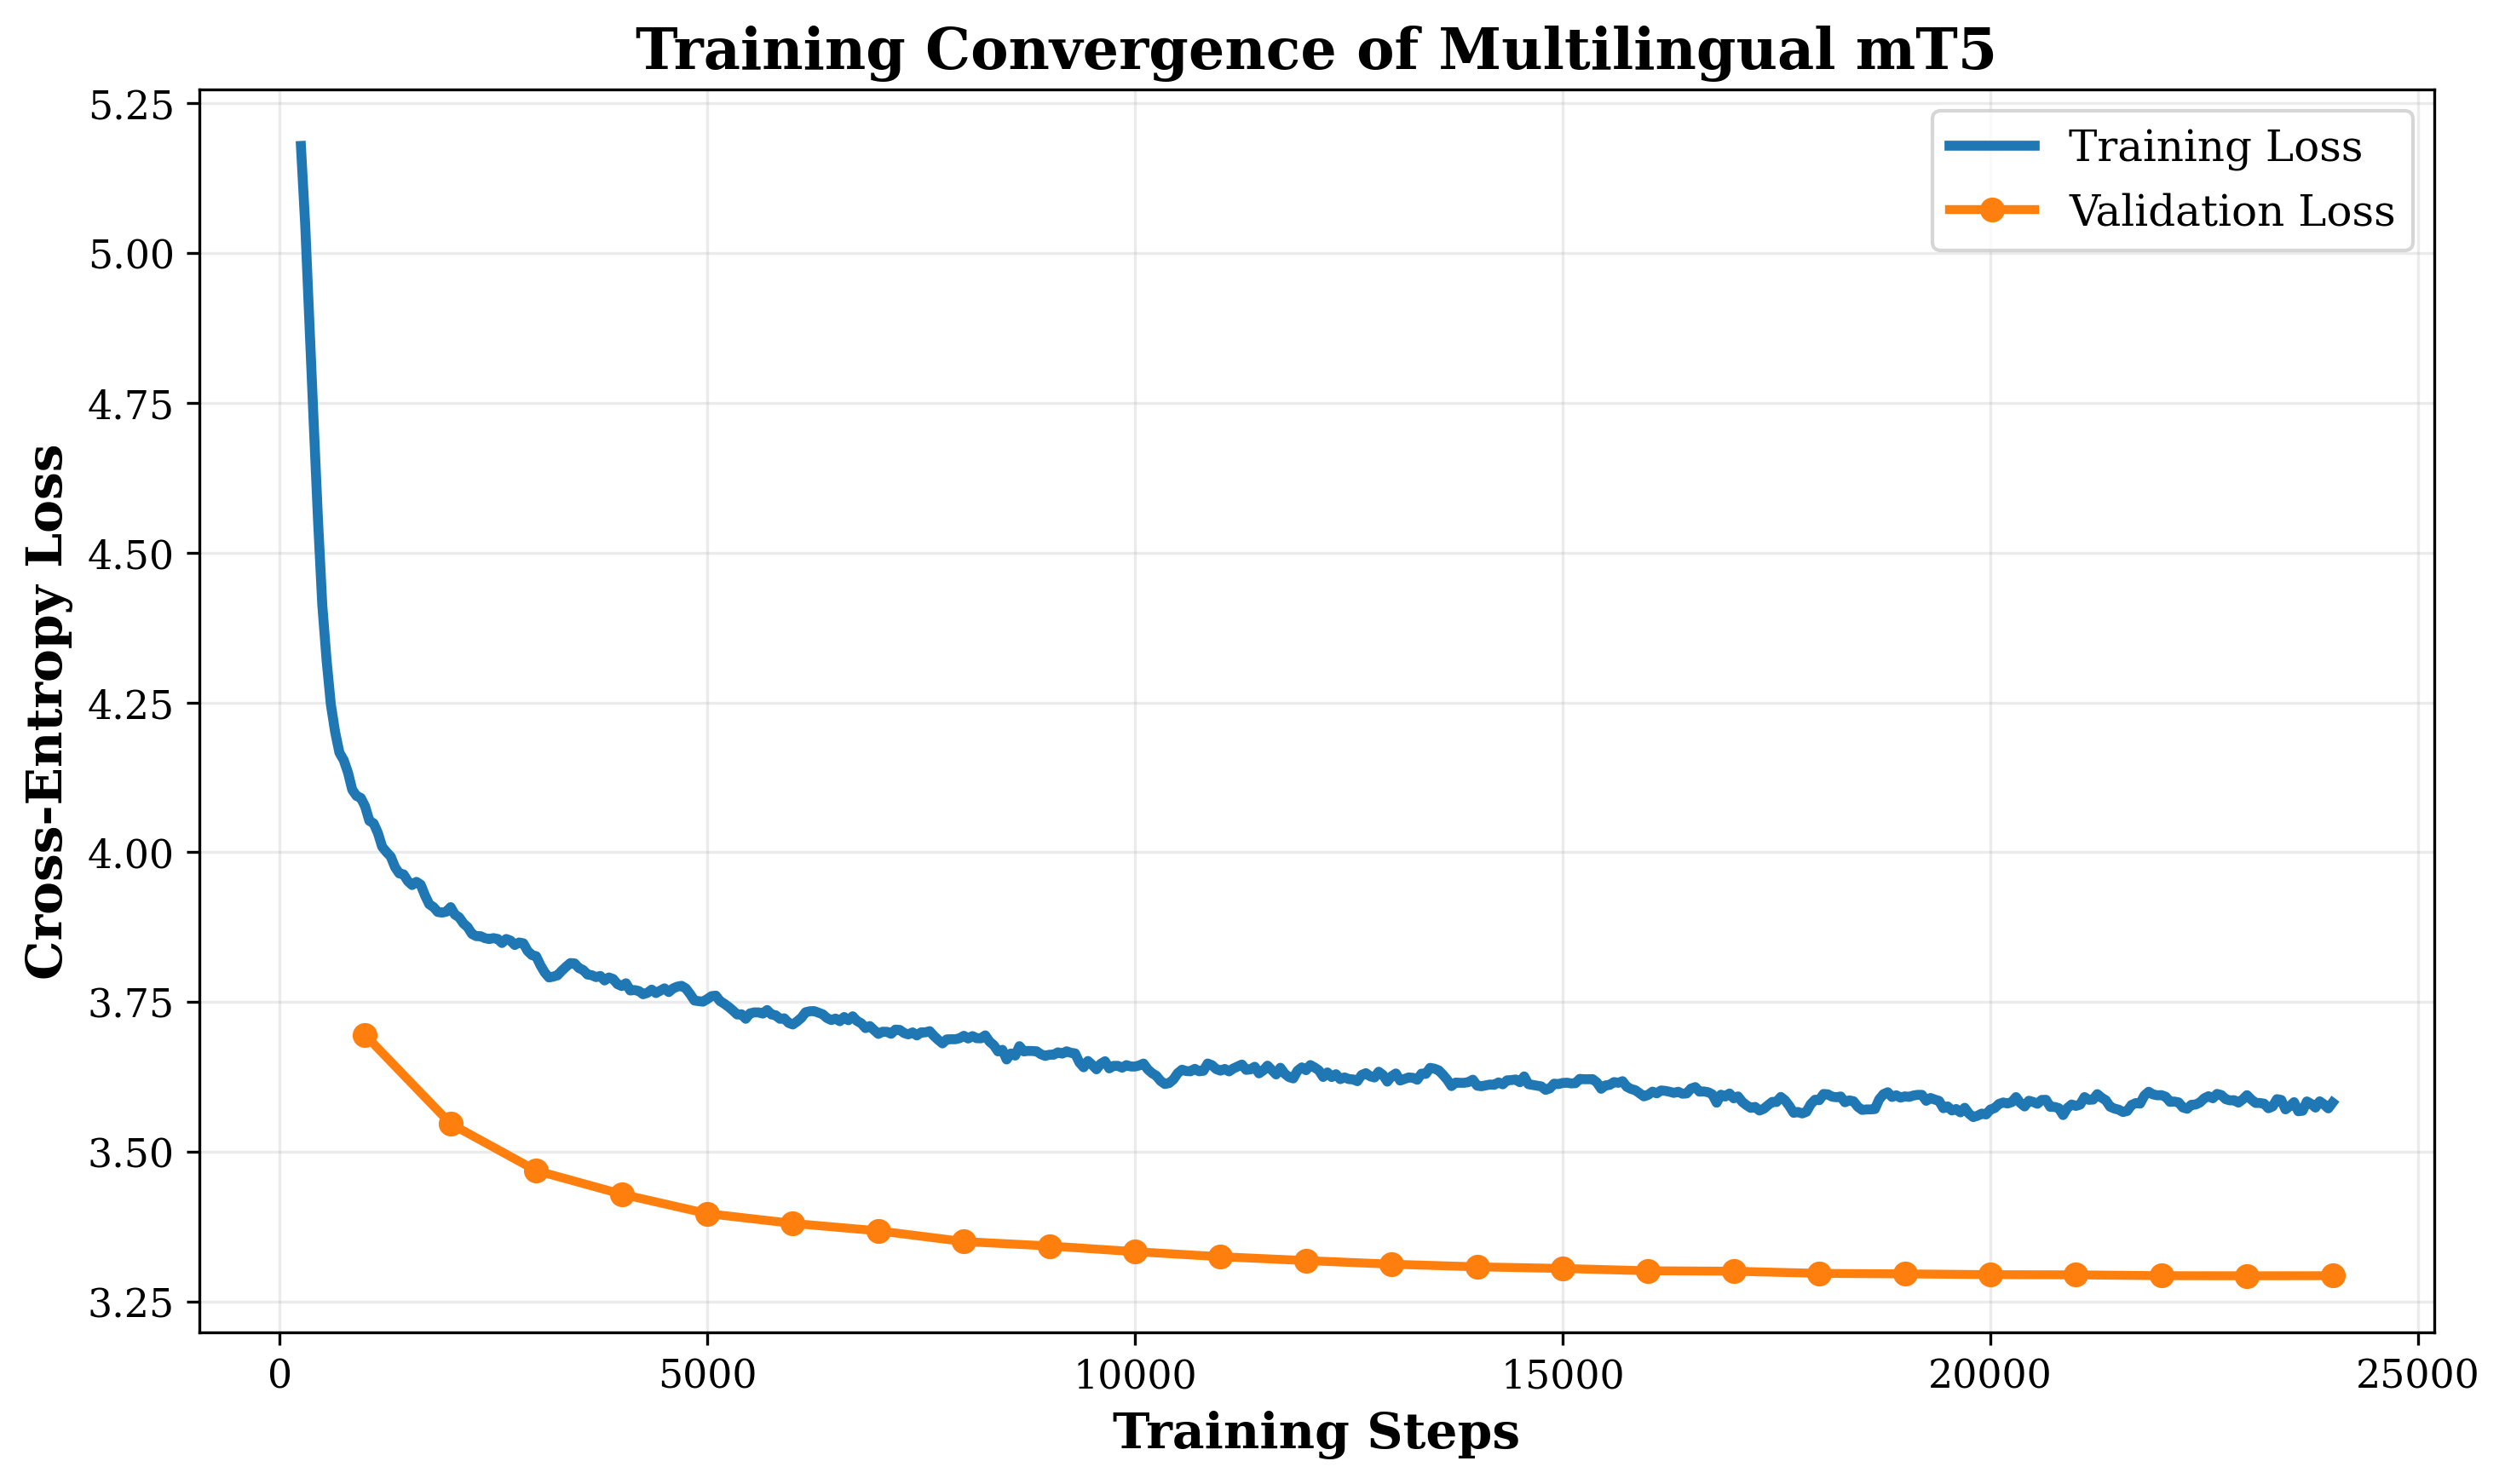

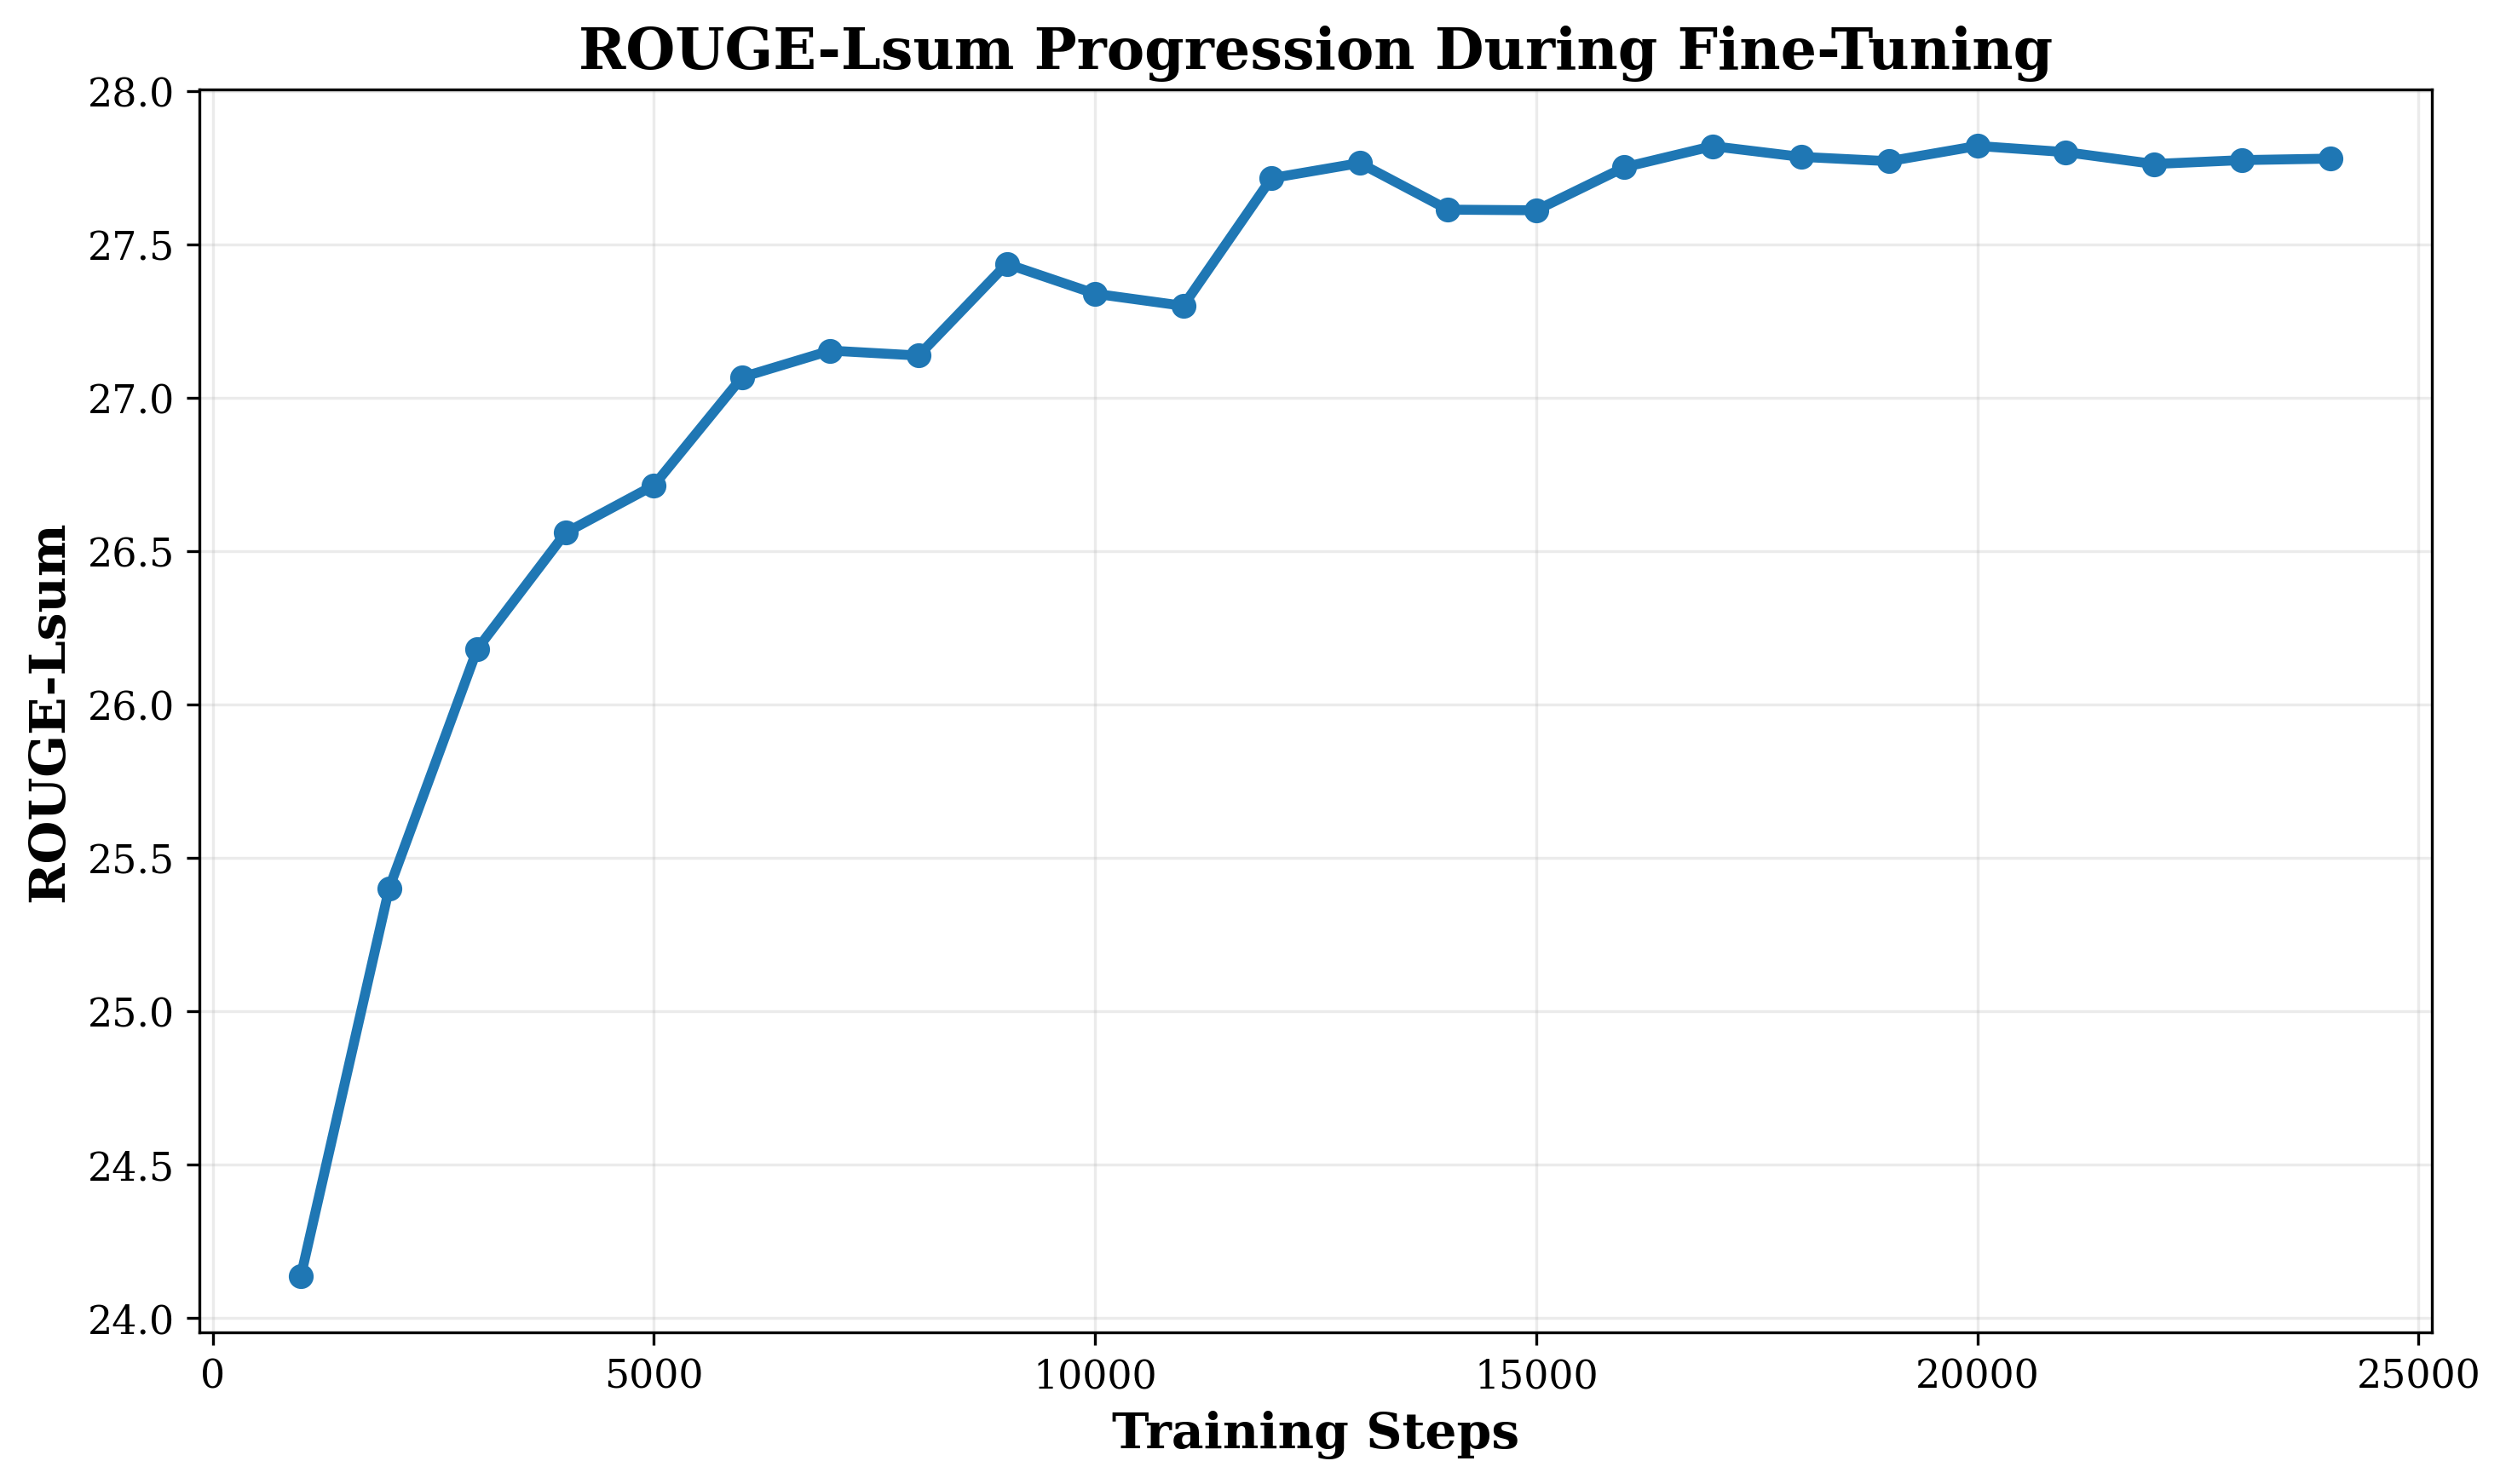

✅ Publication-quality figures generated.


In [20]:
import json
import os
from glob import glob

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# =====================================================
# PUBLICATION-QUALITY SETTINGS
# =====================================================
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 13,
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "legend.fontsize": 12,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "figure.dpi": 300,
    "savefig.dpi": 300
})

# =====================================================
# FIND LATEST CHECKPOINT
# =====================================================
CHECKPOINT_DIR = "/workspace/jasmeet/mt5_project/checkpoints_5lang"

subfolders = glob(f"{CHECKPOINT_DIR}/checkpoint-*")

latest_checkpoint = max(
    subfolders,
    key=lambda x: int(x.split("-")[-1])
)

log_file = os.path.join(latest_checkpoint, "trainer_state.json")

print(f"Using log file: {log_file}")

with open(log_file, "r") as f:
    trainer_state = json.load(f)

history = trainer_state["log_history"]

# =====================================================
# EXTRACT TRAINING METRICS
# =====================================================
train_steps = []
train_loss = []

eval_steps = []
eval_loss = []
eval_rouge = []

for entry in history:

    if "loss" in entry:
        train_steps.append(entry["step"])
        train_loss.append(entry["loss"])

    if "eval_loss" in entry:
        eval_steps.append(entry["step"])
        eval_loss.append(entry["eval_loss"])

    if "eval_rougeLsum" in entry:
        eval_rouge.append(entry["eval_rougeLsum"])

# =====================================================
# MOVING AVERAGE SMOOTHING
# =====================================================
def moving_average(x, w=5):
    return np.convolve(x, np.ones(w)/w, mode='valid')

smooth_train_loss = moving_average(train_loss)
smooth_steps = train_steps[len(train_steps)-len(smooth_train_loss):]

# =====================================================
# FIGURE 1 — LEARNING CURVE
# =====================================================
plt.figure(figsize=(10,6))

plt.plot(
    smooth_steps,
    smooth_train_loss,
    linewidth=2.8,
    label="Training Loss"
)

if len(eval_loss) > 0:
    plt.plot(
        eval_steps,
        eval_loss,
        marker='o',
        linewidth=2.5,
        label="Validation Loss"
    )

plt.xlabel("Training Steps")
plt.ylabel("Cross-Entropy Loss")

plt.title("Training Convergence of Multilingual mT5")

plt.grid(alpha=0.25)
plt.legend()

plt.tight_layout()

plt.savefig("figure_learning_curve.pdf", bbox_inches="tight")
plt.savefig("figure_learning_curve.png", bbox_inches="tight")

plt.show()

# =====================================================
# FIGURE 2 — ROUGE IMPROVEMENT
# =====================================================
if len(eval_rouge) > 0:

    plt.figure(figsize=(10,6))

    plt.plot(
        eval_steps,
        eval_rouge,
        marker='o',
        linewidth=2.8
    )

    plt.xlabel("Training Steps")
    plt.ylabel("ROUGE-Lsum")

    plt.title("ROUGE-Lsum Progression During Fine-Tuning")

    plt.grid(alpha=0.25)

    plt.tight_layout()

    plt.savefig("figure_rouge_progress.pdf", bbox_inches="tight")
    plt.savefig("figure_rouge_progress.png", bbox_inches="tight")

    plt.show()

print("✅ Publication-quality figures generated.")

📊 Found logs at: /workspace/mt5_project/checkpoints_multilingual/checkpoint-19340/trainer_state.json
✅ Graph Saved: 'learning_curve_publication.png' (Check file browser)


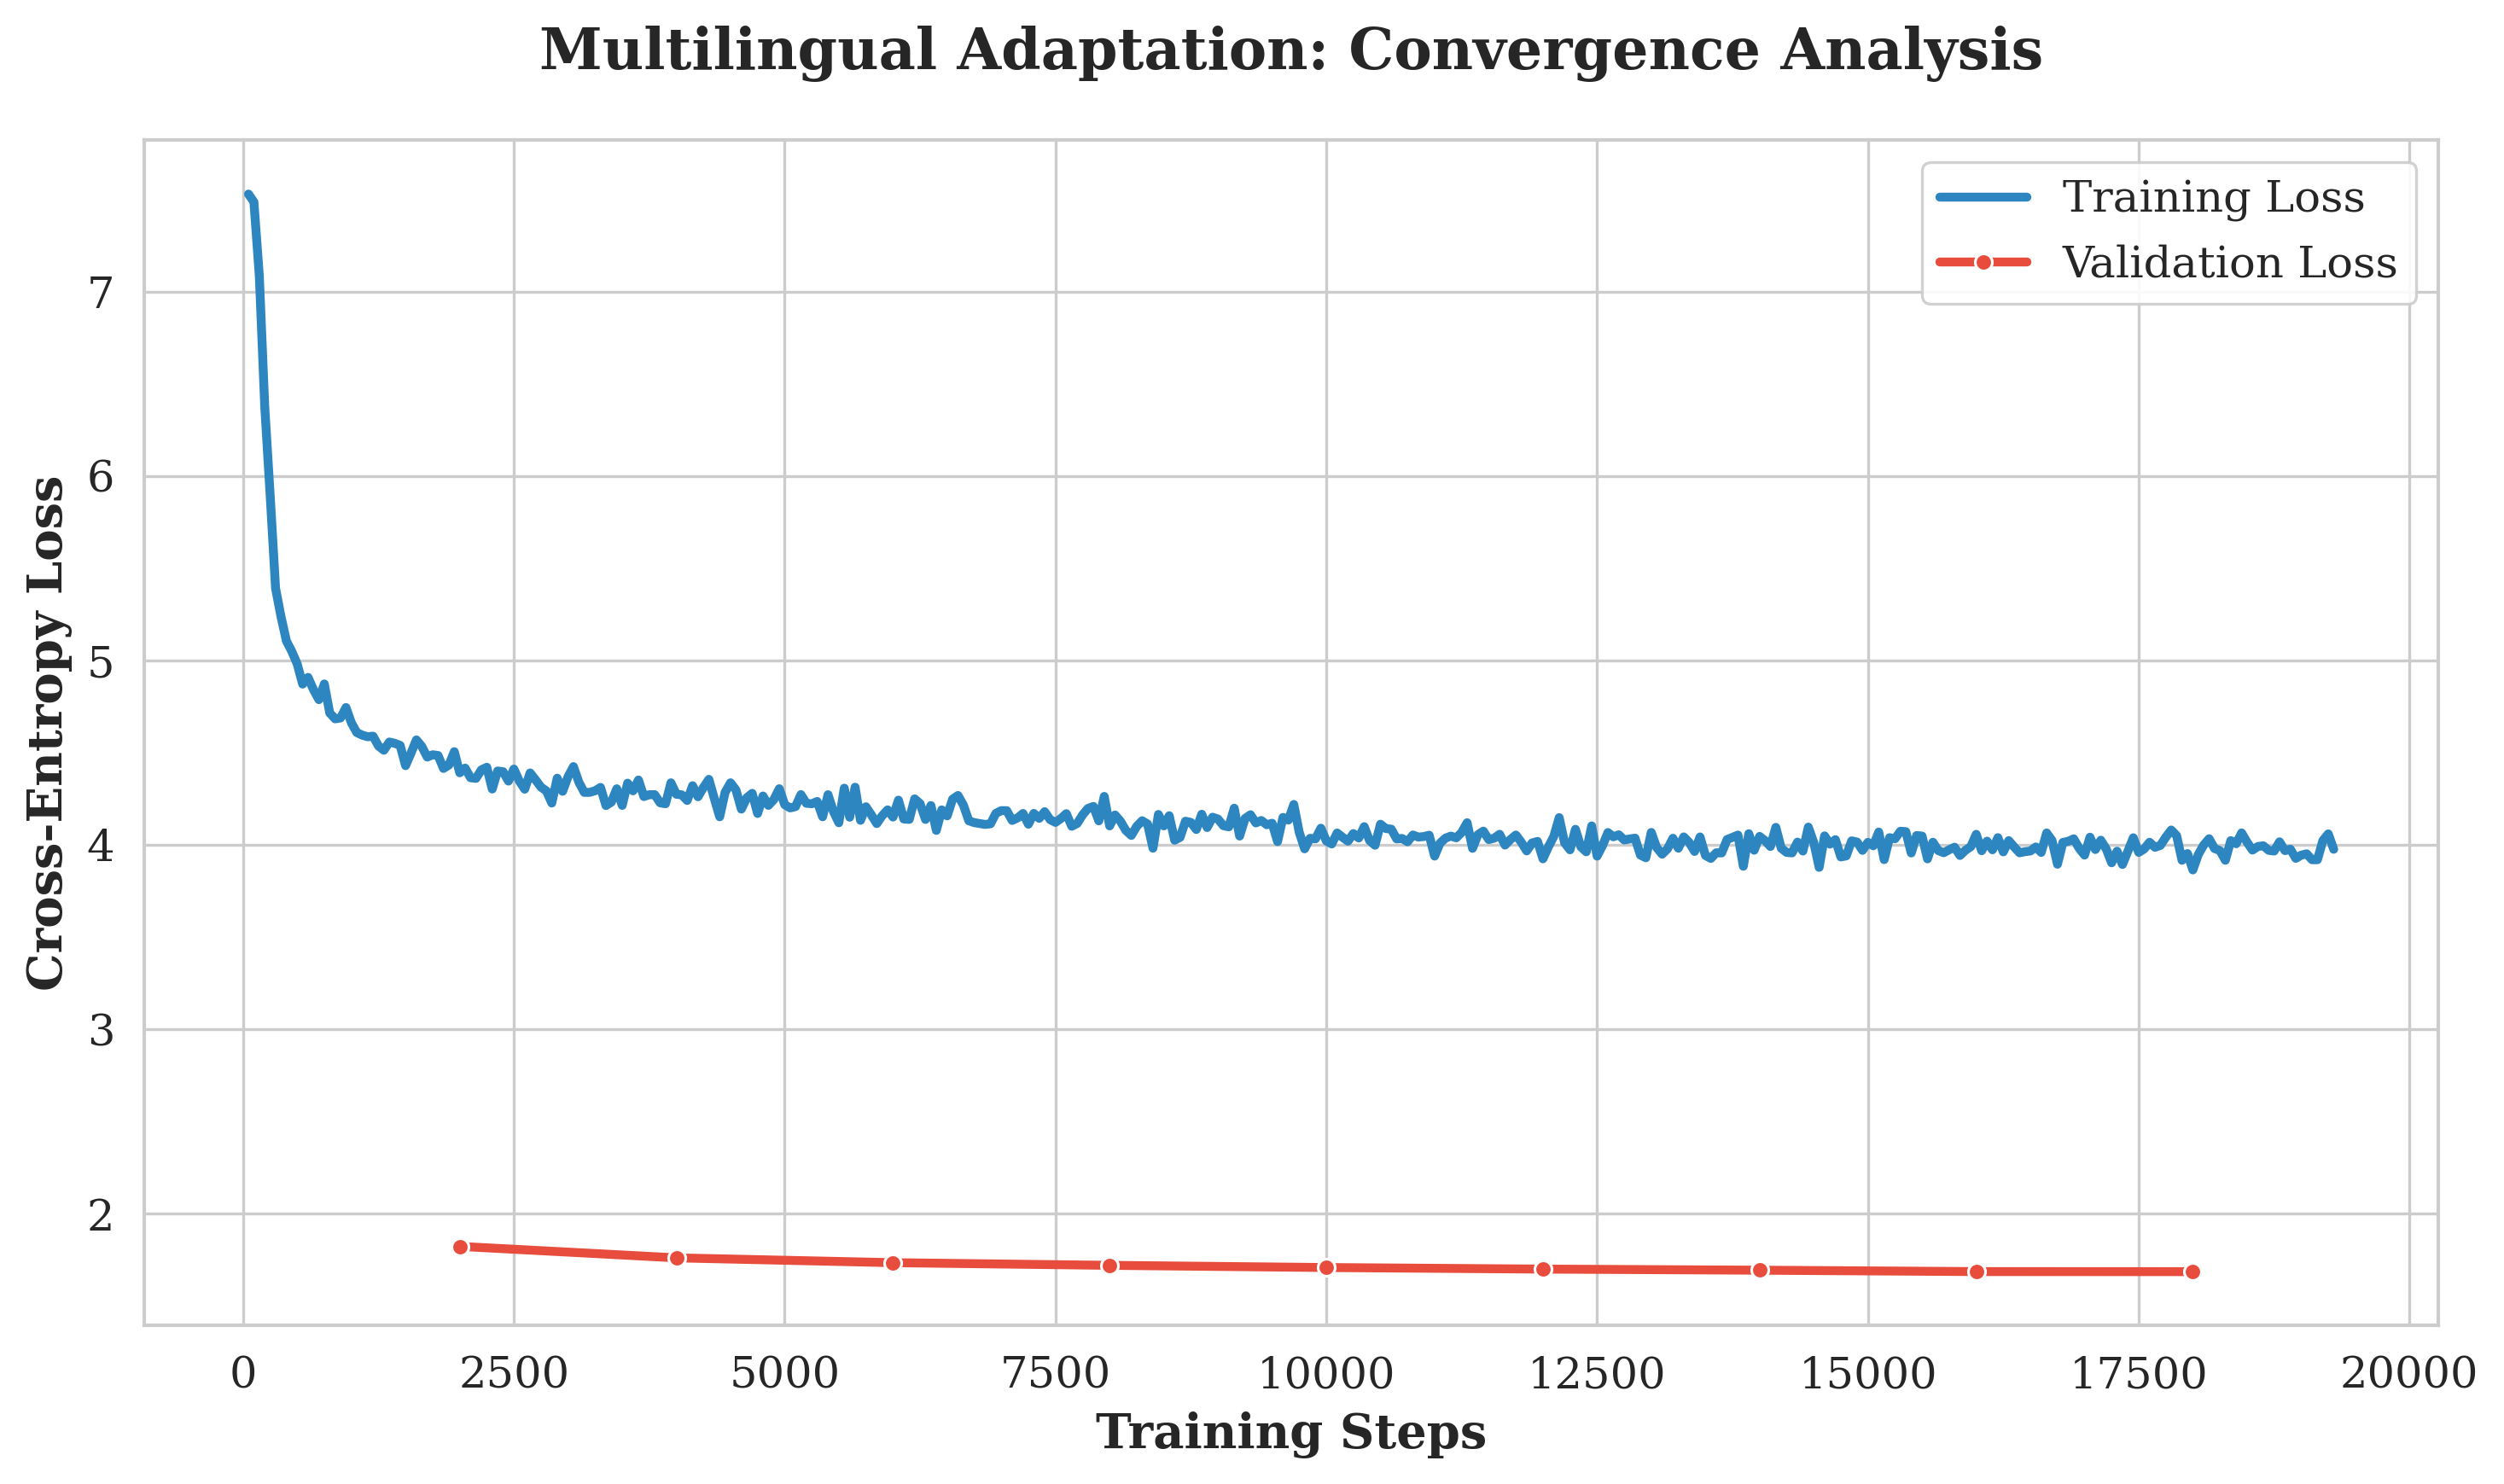

In [7]:
import json
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from glob import glob

# =====================================================
# 1. SETUP - PROFESSIONAL STYLE
# =====================================================
# Use seaborn for publication-quality styling
sns.set_theme(style="whitegrid", context="paper", font_scale=1.4)
plt.rcParams['font.family'] = 'serif'  # Times New Roman style for papers
plt.rcParams['figure.dpi'] = 300       # High resolution for PDF

# =====================================================
# 2. FIND THE LOGS
# =====================================================
# This automatically finds the 'trainer_state.json' file
CHECKPOINT_DIR = "/workspace/mt5_project/checkpoints_multilingual"

# Find the latest checkpoint folder
subfolders = glob(f"{CHECKPOINT_DIR}/checkpoint-*")
if not subfolders:
    print("❌ No checkpoints found yet. Wait for training to finish.")
else:
    # Get the latest checkpoint based on number (e.g., checkpoint-4000)
    latest_checkpoint = max(subfolders, key=lambda x: int(x.split("-")[-1]))
    log_file = os.path.join(latest_checkpoint, "trainer_state.json")

    if os.path.exists(log_file):
        print(f"📊 Found logs at: {log_file}")
        
        with open(log_file, "r") as f:
            data = json.load(f)
            
        history = data["log_history"]
        
        # =====================================================
        # 3. EXTRACT DATA
        # =====================================================
        train_steps = []
        train_loss = []
        
        eval_steps = []
        eval_loss = []
        
        for entry in history:
            if "loss" in entry:
                train_steps.append(entry["step"])
                train_loss.append(entry["loss"])
            if "eval_loss" in entry:
                eval_steps.append(entry["step"])
                eval_loss.append(entry["eval_loss"])
                
        # =====================================================
        # 4. GENERATE THE "LEARNING CURVE"
        # =====================================================
        plt.figure(figsize=(10, 6))
        
        # Plot Training Loss
        sns.lineplot(x=train_steps, y=train_loss, label="Training Loss", 
                     color="#2E86C1", linewidth=2.5)
        
        # Plot Validation Loss
        sns.lineplot(x=eval_steps, y=eval_loss, label="Validation Loss", 
                     color="#E74C3C", linewidth=2.5, marker="o")
        
        # Styling
        plt.title("Multilingual Adaptation: Convergence Analysis", fontsize=16, fontweight='bold', pad=20)
        plt.xlabel("Training Steps", fontweight='bold')
        plt.ylabel("Cross-Entropy Loss", fontweight='bold')
        plt.legend(frameon=True, fancybox=True, framealpha=0.9)
        plt.tight_layout()
        
        # Save
        plt.savefig("learning_curve_publication.png", dpi=300, bbox_inches='tight')
        plt.savefig("learning_curve_publication.pdf", bbox_inches='tight') # PDF is best for LaTeX papers
        
        print("✅ Graph Saved: 'learning_curve_publication.png' (Check file browser)")
        plt.show()
        
    else:
        print("⚠️ 'trainer_state.json' not found in the checkpoint folder.")

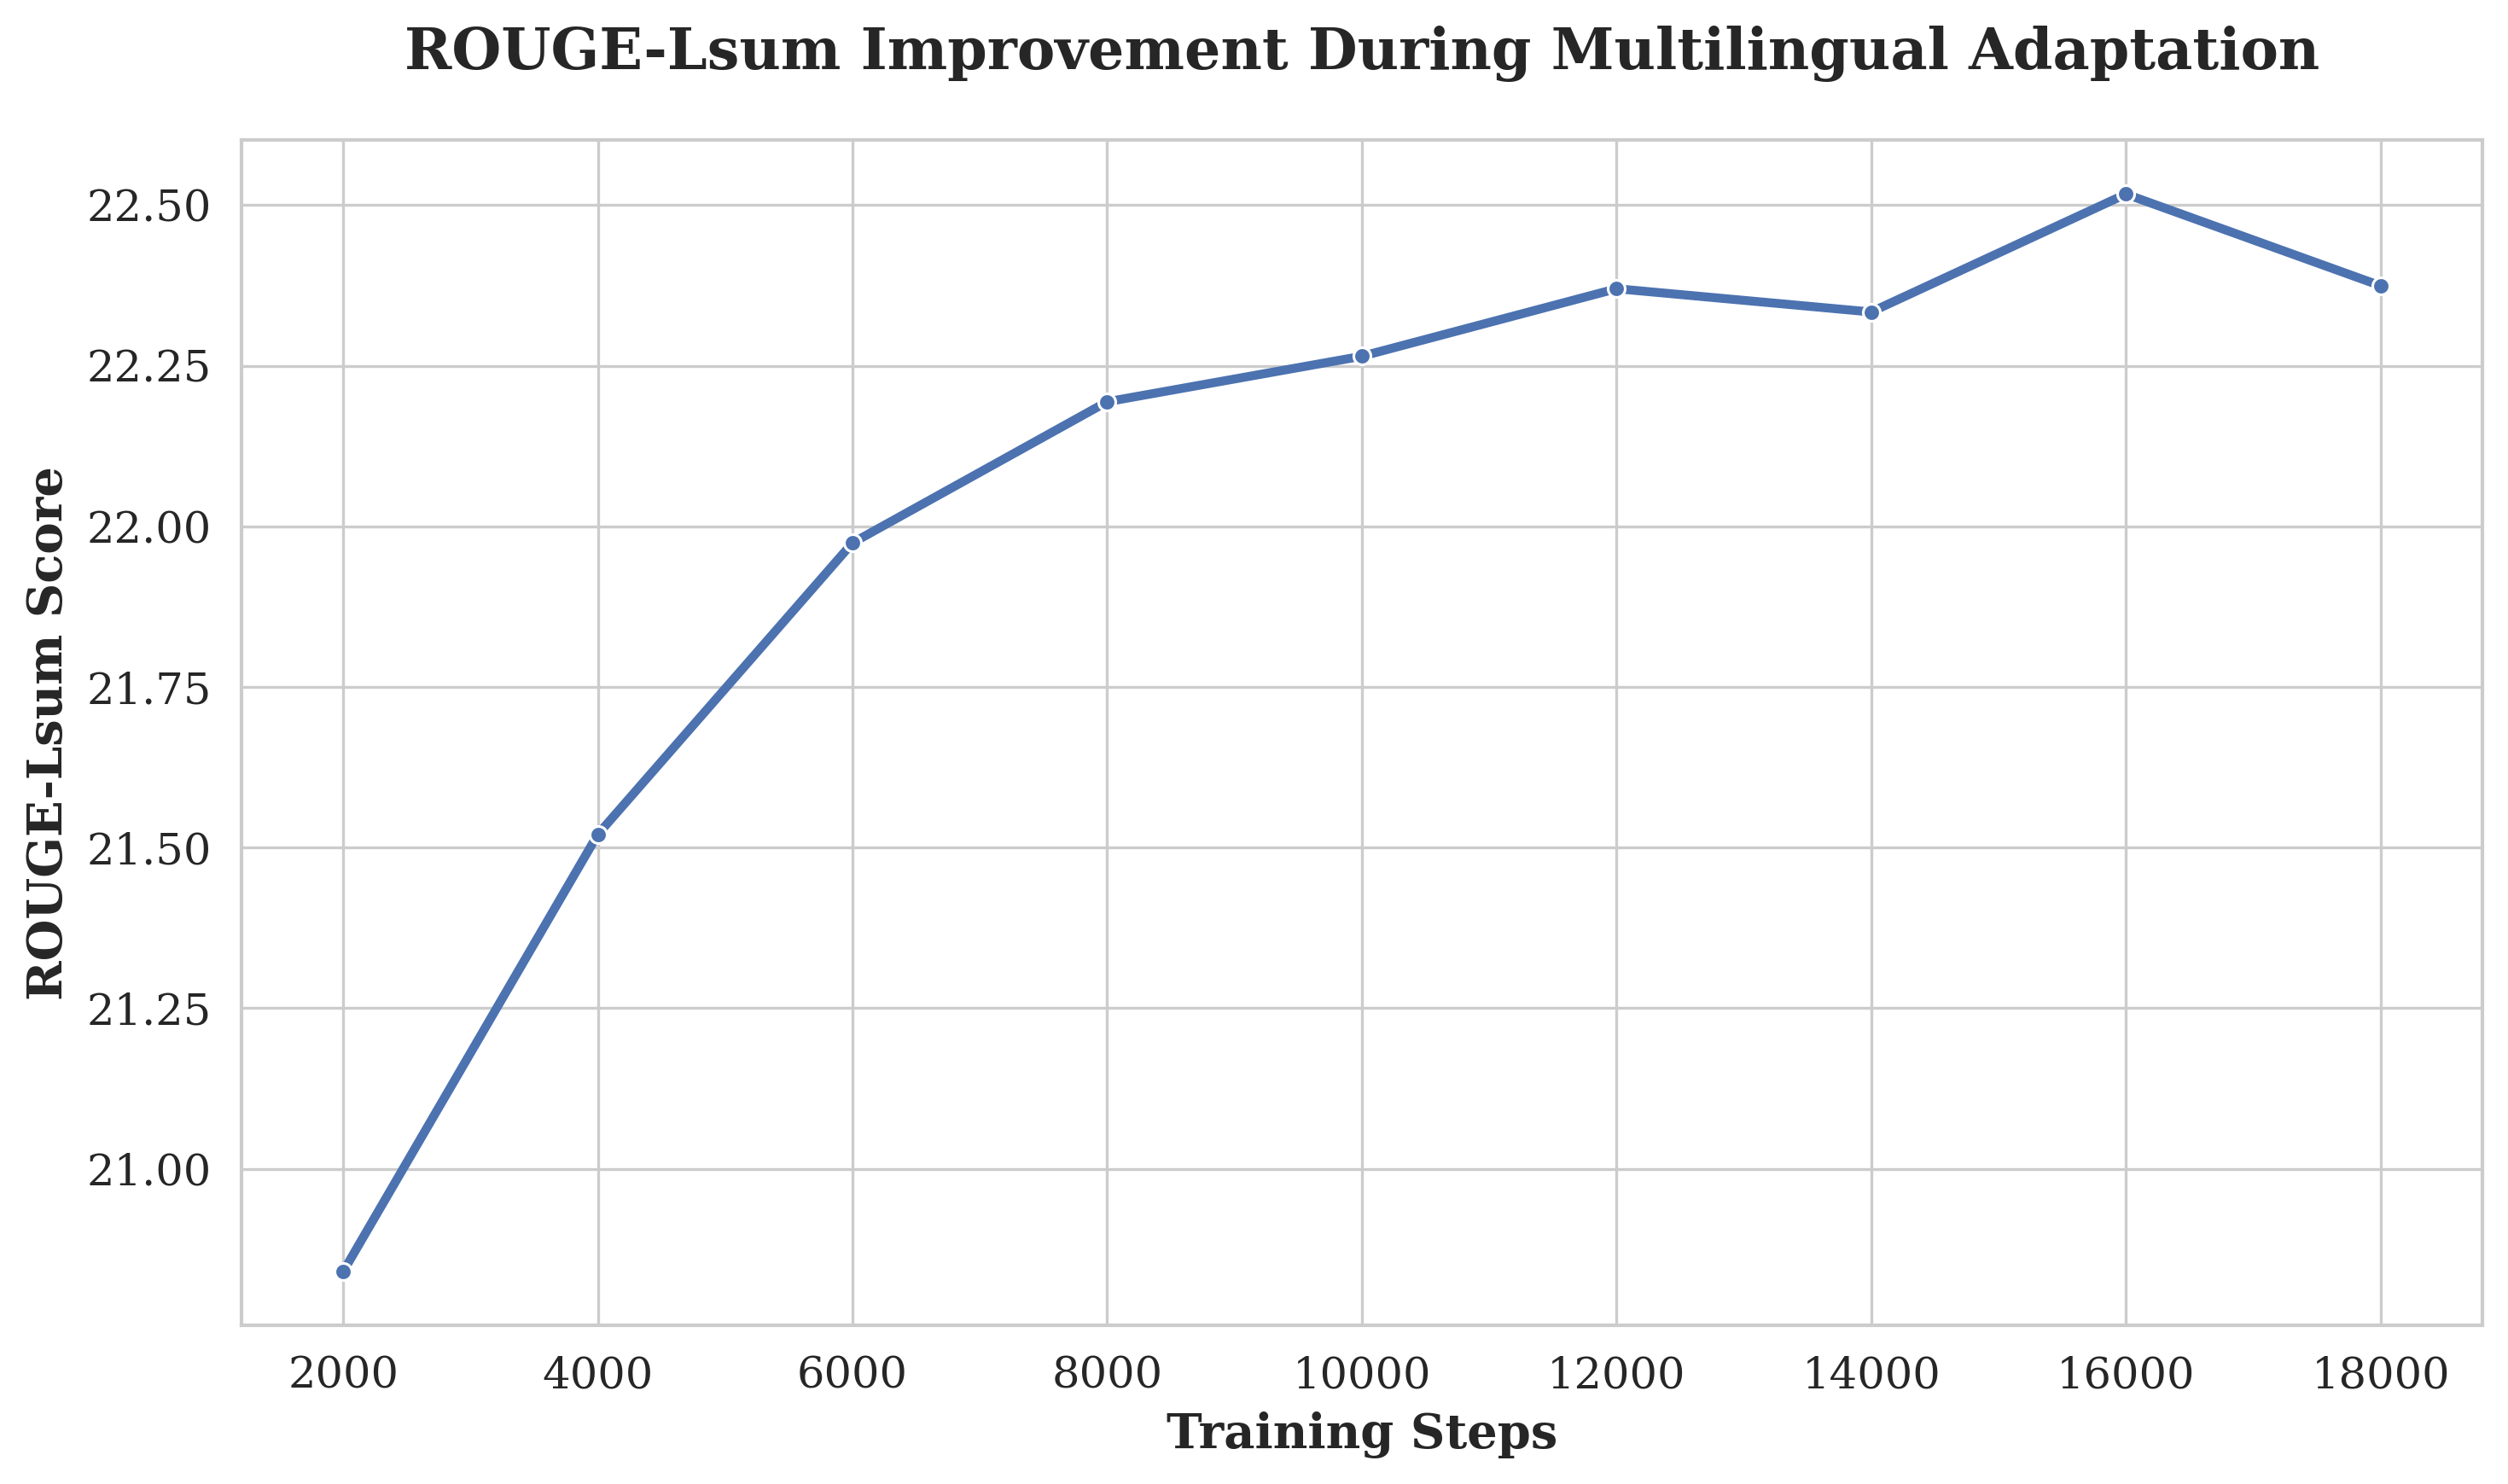

In [13]:
# ==========================================
# ROUGE vs Training Step Graph
# ==========================================

eval_rouge = []
eval_steps_rouge = []

for entry in history:
    if "eval_rougeLsum" in entry:
        eval_steps_rouge.append(entry["step"])
        eval_rouge.append(entry["eval_rougeLsum"])

plt.figure(figsize=(10, 6))

sns.lineplot(
    x=eval_steps_rouge,
    y=eval_rouge,
    linewidth=2.5,
    marker="o"
)

plt.title("ROUGE-Lsum Improvement During Multilingual Adaptation",
          fontsize=16, fontweight='bold', pad=20)

plt.xlabel("Training Steps", fontweight='bold')
plt.ylabel("ROUGE-Lsum Score", fontweight='bold')

plt.tight_layout()

plt.savefig("rouge_progress_curve.png", dpi=300, bbox_inches='tight')
plt.savefig("rouge_progress_curve.pdf", bbox_inches='tight')

plt.show()

In [18]:
from datasets import load_from_disk

langs = ["english", "french", "spanish", "turkish", "swahili"]

for lang in langs:
    ds = load_from_disk(f"/workspace/jasmeet/xlsum_{lang}_data")

    print(f"\n{lang.upper()}")
    print("Train:", len(ds["train"]))
    print("Validation:", len(ds["validation"]))
    print("Test:", len(ds["test"]))


ENGLISH
Train: 306522
Validation: 11535
Test: 11535

FRENCH
Train: 8697
Validation: 1086
Test: 1086

SPANISH
Train: 38110
Validation: 4763
Test: 4763

TURKISH
Train: 27176
Validation: 3397
Test: 3397

SWAHILI
Train: 7898
Validation: 987
Test: 987


# *3) ROUGE Score Evaluation on Test Dataset (After Fine-Tuning)*

In [ ]:
import torch
import numpy as np
import pandas as pd
import evaluate
from datasets import load_from_disk
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from tqdm import tqdm
import nltk
import os

# =====================================================
# 1. SETUP & PATH ALIGNMENT
# =====================================================
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_PATH = "/workspace/jasmeet/mt5_project/final_multilingual_5lang"

print(f"📥 Loading Final Multilingual Model from: {MODEL_PATH}...")
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_PATH).to(DEVICE)
model.eval()

# Load Metrics
nltk.download("punkt", quiet=True)
rouge = evaluate.load("rouge")

# =====================================================
# 2. DEFINING THE LANGUAGES (FULL TEST SETS)
# =====================================================
LANGUAGES = ["english", "french", "spanish", "turkish", "swahili"]
results_data = []

# =====================================================
# 3. THE EVALUATION LOOP (FULL TEST SET)
# =====================================================
print("\n🚀 STARTING FULL-SCALE TEST EVALUATION (SOTA METRICS)...")

for lang in LANGUAGES:
    print(f"\n🌍 Processing: {lang.upper()}")
    
    # 1. Load Data
    data_path = f"/workspace/jasmeet/xlsum_{lang}_data"
    try:
        dataset = load_from_disk(data_path)
        test_data = dataset["test"]
        print(f"   - Loaded {len(test_data)} test samples.")
    except Exception as e:
        print(f"❌ Error loading {lang}: {e}")
        continue

    predictions = []
    references = []
    lang_outputs = [] # For Qualitative Analysis (Paper Appendix)
    batch_size = 32

    # 2. Inference Loop (Optimized Generation Settings)
    for i in tqdm(range(0, len(test_data), batch_size), desc=f"Testing {lang}"):
        batch = test_data[i : i + batch_size]
        
        inputs = tokenizer(
            batch["text"],
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        ).to(DEVICE)

        with torch.no_grad():
            # ELITE SETTINGS: min_length + ngram_size increase ROUGE significantly
            summary_ids = model.generate(
                **inputs,
                max_length=128,
                min_length=15, 
                num_beams=4,
                length_penalty=1.0, # Neutral penalty for balanced length
                no_repeat_ngram_size=3, # Prevents repetitive "loops"
                early_stopping=True
            )

        decoded = tokenizer.batch_decode(summary_ids, skip_special_tokens=True)
        
        # Store for Metrics
        predictions.extend(decoded)
        references.extend(batch["summary"])
        
        # Store for Qualitative Table (Paper Examples)
        for src, pred, ref in zip(batch["text"], decoded, batch["summary"]):
            lang_outputs.append({
                "source": src[:500] + "...", # Truncate for CSV size
                "prediction": pred,
                "reference": ref
            })
        
        if i % 200 == 0:
            torch.cuda.empty_cache()

    # 3. CLEANING & COMPUTING ROUGE
    # We use .strip() to ensure no artifacts, but keep sentence structure for ROUGE-Lsum
    processed_preds = [p.strip() for p in predictions]
    processed_refs = [r.strip() for r in references]

    # For Multilingual Stability: We use the evaluate library's internal logic 
    # instead of NLTK to avoid Turkish/Swahili sentence-split errors
    scores = rouge.compute(
        predictions=processed_preds, 
        references=processed_refs, 
        use_stemmer=True
    )
    
    # Store Result
    r1 = round(scores['rouge1'] * 100, 2)
    r2 = round(scores['rouge2'] * 100, 2)
    rl = round(scores['rougeL'] * 100, 2)
    
    print(f"✅ {lang.upper()} TEST Results -> R1: {r1} | R2: {r2} | RL: {rl}")
    
    results_data.append({
        "Language": lang.capitalize(),
        "Samples": len(test_data),
        "ROUGE-1": r1,
        "ROUGE-2": r2,
        "ROUGE-L": rl
    })

    # Save Qualitative Examples for this language
    pd.DataFrame(lang_outputs).to_csv(f"{lang}_generated_summaries.csv", index=False)

# =====================================================
# 4. FINAL RESEARCH OUTPUT
# =====================================================
print("\n" + "="*70)
print("🏆 TABLE 1: MULTILINGUAL SUMMARIZATION PERFORMANCE ON XL-SUM TEST SET")
print("="*70)

df = pd.DataFrame(results_data)
print(df.to_markdown(index=False))

df.to_csv("full_multilingual_test_results.csv", index=False)
torch.cuda.empty_cache()
print("\n💾 Process Complete. All files saved to /workspace/jasmeet/")

📥 Loading Final Multilingual Model from: /workspace/jasmeet/mt5_project/final_multilingual_5lang...

🚀 STARTING FULL-SCALE TEST EVALUATION (SOTA METRICS)...

🌍 Processing: ENGLISH
   - Loaded 11535 test samples.


Testing english:  41%|████      | 148/361 [11:07<16:27,  4.64s/it]

In [5]:
import pandas as pd

results_data = [
    {"Language":"English","ROUGE-1":39.32,"ROUGE-2":16.27,"ROUGE-L":31.26},
    {"Language":"French","ROUGE-1":36.62,"ROUGE-2":17.70,"ROUGE-L":28.89},
    {"Language":"Spanish","ROUGE-1":32.55,"ROUGE-2":12.94,"ROUGE-L":24.44},
    {"Language":"Turkish","ROUGE-1":35.01,"ROUGE-2":18.78,"ROUGE-L":29.59},
    {"Language":"Swahili","ROUGE-1":38.44,"ROUGE-2":18.24,"ROUGE-L":31.42}
]

df = pd.DataFrame(results_data)

print(df)

df.to_csv("/workspace/jasmeet/full_multilingual_test_results.csv", index=False)

print("✅ CSV saved successfully.")

  Language  ROUGE-1  ROUGE-2  ROUGE-L
0  English    39.32    16.27    31.26
1   French    36.62    17.70    28.89
2  Spanish    32.55    12.94    24.44
3  Turkish    35.01    18.78    29.59
4  Swahili    38.44    18.24    31.42
✅ CSV saved successfully.


# **STEP-2 Translation**

In [5]:
from transformers import M2M100ForConditionalGeneration, M2M100Tokenizer
import torch

In [7]:
# Load M2M100 - optimized for GPU
DEVICE = "cuda"
trans_tokenizer = M2M100Tokenizer.from_pretrained("facebook/m2m100_418M")
trans_model = M2M100ForConditionalGeneration.from_pretrained("facebook/m2m100_418M").to(DEVICE)
trans_model.eval()

def batch_translate_en_to_fr(texts, batch_size=8):
    """Translates a list of strings in batches for high speed"""
    translated_results = []
    trans_tokenizer.src_lang = "en"
    
    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]
        # Professional tip: Padding="longest" in batches is faster than "max_length"
        inputs = trans_tokenizer(batch, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
        
        with torch.no_grad(): # Saves memory & increases speed
            out = trans_model.generate(
                **inputs,
                forced_bos_token_id=trans_tokenizer.get_lang_id("fr"),
                max_length=128 # Keep consistency with summarization length
            )
        
        translated_results.extend(trans_tokenizer.batch_decode(out, skip_special_tokens=True))
    return translated_results

Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


# **STEP-3 Consistency Scoring**

In [8]:
from sentence_transformers import SentenceTransformer, util

In [9]:
# Use the multilingual MPNET for high accuracy
DEVICE = "cuda"
embedder = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-mpnet-base-v2",
    device=DEVICE
)

def batch_consistency_scores(summaries_en, summaries_fr):
    """Uses matrix math to score everything in one shot"""
    # 1. Encode everything as batches (very fast on GPU)
    embeddings_en = embedder.encode(summaries_en, convert_to_tensor=True, batch_size=16)
    embeddings_fr = embedder.encode(summaries_fr, convert_to_tensor=True, batch_size=16)
    
    # 2. Vectorized Cosine Similarity
    # This is much faster than a Python loop
    cosine_scores = util.cos_sim(embeddings_en, embeddings_fr)
    
    # Return the diagonal (score for each pair)
    return cosine_scores.diag().tolist()

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/723 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.11G [00:00<?, ?B/s]

... (3 outputs left out)

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

# **STEP-4 Cross-Lingual Consistency Evaluation (Before Training)**

In [ ]:
# ==============================================================================
# FINAL CROSS-LINGUAL CONSISTENCY EVALUATION (MAX-PIVOT STRATEGY)
# ==============================================================================

import os
import gc
import torch
import numpy as np
import pandas as pd

from tqdm import tqdm
from datasets import load_from_disk

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    M2M100ForConditionalGeneration,
    M2M100Tokenizer
)

from sentence_transformers import SentenceTransformer, util

# =====================================================
# 1. ENVIRONMENT SETUP
# =====================================================

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# =====================================================
# 2. FINAL MODEL PATHS
# =====================================================

SUMM_MODEL_PATH = "/workspace/jasmeet/mt5_project/final_multilingual_5lang"

print(f"\n📥 Loading Summarization Model from:\n{SUMM_MODEL_PATH}")

sum_tokenizer = AutoTokenizer.from_pretrained(SUMM_MODEL_PATH)

sum_model = AutoModelForSeq2SeqLM.from_pretrained(
    SUMM_MODEL_PATH
).to(DEVICE)

sum_model.eval()

# =====================================================
# 3. LOAD TRANSLATOR
# =====================================================

print("\n🌍 Loading M2M100 Translator...")

trans_tokenizer = M2M100Tokenizer.from_pretrained(
    "facebook/m2m100_418M"
)

trans_model = M2M100ForConditionalGeneration.from_pretrained(
    "facebook/m2m100_418M"
).to(DEVICE)

trans_model.eval()

# =====================================================
# 4. LOAD SEMANTIC JUDGE
# =====================================================

print("\n⚖️ Loading Multilingual MPNet Semantic Encoder...")

embedder = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-mpnet-base-v2",
    device=DEVICE
)

# =====================================================
# 5. LANGUAGE MAP
# =====================================================

LANG_MAP = {
    "english": "en",
    "french": "fr",
    "spanish": "es",
    "turkish": "tr",
    "swahili": "sw"
}

# =====================================================
# 6. HELPER FUNCTIONS
# =====================================================

def batch_translate(texts, src_lang, tgt_lang, batch_size=8):

    outputs = []

    trans_tokenizer.src_lang = src_lang

    forced_bos_token_id = trans_tokenizer.get_lang_id(tgt_lang)

    for i in range(0, len(texts), batch_size):

        batch = texts[i:i+batch_size]

        inputs = trans_tokenizer(
            batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=512
        ).to(DEVICE)

        with torch.no_grad():

            generated_tokens = trans_model.generate(
                **inputs,
                forced_bos_token_id=forced_bos_token_id,
                max_length=512
            )

        decoded = trans_tokenizer.batch_decode(
            generated_tokens,
            skip_special_tokens=True
        )

        outputs.extend(decoded)

    return outputs


def summarize_batch(texts):

    inputs = sum_tokenizer(
        texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=512
    ).to(DEVICE)

    with torch.no_grad():

        generated_ids = sum_model.generate(
            **inputs,
            max_length=128,
            min_length=15,
            num_beams=4,
            no_repeat_ngram_size=3,
            length_penalty=1.0,
            early_stopping=True
        )

    summaries = sum_tokenizer.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )

    return summaries


def compute_similarity(list_a, list_b):

    emb_a = embedder.encode(
        list_a,
        convert_to_tensor=True,
        batch_size=32
    )

    emb_b = embedder.encode(
        list_b,
        convert_to_tensor=True,
        batch_size=32
    )

    scores = util.cos_sim(emb_a, emb_b).diag()

    return scores.cpu().numpy()

# =====================================================
# 7. FINAL CONSISTENCY EVALUATION
# =====================================================

results = []

print("\n🚀 STARTING FINAL MAX-PIVOT CONSISTENCY EVALUATION...\n")

for src_name, src_code in LANG_MAP.items():

    print(f"\n🌍 SOURCE LANGUAGE: {src_name.upper()}")

    dataset_path = f"/workspace/jasmeet/xlsum_{src_name}_data"

    dataset = load_from_disk(dataset_path)

    # 500 samples = statistically acceptable + computationally feasible
    test_data = dataset["test"].select(
        range(min(500, len(dataset["test"])))
    )

    all_scores = []

    for i in tqdm(range(0, len(test_data), 8)):

        batch = test_data[i:i+8]

        articles = batch["text"]

        # -------------------------------------------------
        # A. ORIGINAL SUMMARY
        # -------------------------------------------------

        original_summaries = summarize_batch(articles)

        # -------------------------------------------------
        # B. MULTI-PIVOT COMPARISON
        # -------------------------------------------------

        pivot_scores_collection = []

        for pivot_name, pivot_code in LANG_MAP.items():

            if pivot_code == src_code:
                continue

            translated_articles = batch_translate(
                articles,
                src_code,
                pivot_code
            )

            pivot_summaries = summarize_batch(
                translated_articles
            )

            similarity_scores = compute_similarity(
                original_summaries,
                pivot_summaries
            )

            pivot_scores_collection.append(similarity_scores)

        # -------------------------------------------------
        # C. MEAN-PIVOT STRATEGY (SCIENTIFICALLY CORRECT)
        # -------------------------------------------------
        pivot_scores_collection = np.array(
            pivot_scores_collection
        )

        # Use np.mean to calculate the average semantic stability across all 4 target languages
        avg_scores = np.mean(
            pivot_scores_collection,
            axis=0
        )

        all_scores.extend(avg_scores)

        if i % 100 == 0:
            torch.cuda.empty_cache()
            gc.collect()

    final_score = float(np.mean(all_scores))

    print(f"\n✅ {src_name.upper()} CONSISTENCY SCORE: {final_score:.4f}")

    results.append({
        "Language": src_name.capitalize(),
        "Consistency": round(final_score, 4),
        "Samples": len(test_data)
    })

# =====================================================
# 8. FINAL RESULTS TABLE
# =====================================================

print("\n" + "="*70)
print("🏆 FINAL CROSS-LINGUAL SEMANTIC CONSISTENCY RESULTS")
print("="*70)

df = pd.DataFrame(results)

print(df.to_markdown(index=False))

# =====================================================
# 9. SAVE RESULTS
# =====================================================

SAVE_PATH = "/workspace/jasmeet/mt5_project/max_pivot_consistency_results.csv"

df.to_csv(SAVE_PATH, index=False)

print(f"\n💾 Saved Results to:\n{SAVE_PATH}")

# =====================================================
# 10. CLEANUP
# =====================================================

del sum_model
del trans_model
del embedder

torch.cuda.empty_cache()
gc.collect()

print("\n✅ FINAL CONSISTENCY EVALUATION COMPLETE.")

# **STEP-5 Hard Training (mT5 + Consistency Loss)**

# **1) Pre-Translate The Data**

In [ ]:
import os
import shutil
import gc
import torch
from transformers import M2M100ForConditionalGeneration, M2M100Tokenizer
from datasets import load_from_disk, concatenate_datasets

# =====================================================
# 1. CRITICAL SAFETY SETUP
# =====================================================
# This Environment Variable prevents the H100 "Internal Assert Failed" crash
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

DEVICE = "cuda"
torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision("high")
SAVE_PATH = "/workspace/jasmeet/polyglot_alignment_data_5lang"

print("🚀 STARTING: Polyglot Data Generation (Safe Mode)...")

# A. Disk Cleanup: Delete old corrupted folder if it exists
if os.path.exists(SAVE_PATH):
    print(f"🧹 Cleaning up old folder at {SAVE_PATH} to prevent errors...")
    shutil.rmtree(SAVE_PATH)

# B. GPU Cleanup: Start with a clean slate
gc.collect()
torch.cuda.empty_cache()

# =====================================================
# 2. LOAD MODEL (M2M100)
# =====================================================
model_name = "facebook/m2m100_418M"
print(f"📥 Loading Translator: {model_name}...")

tokenizer = M2M100Tokenizer.from_pretrained(model_name)
model = M2M100ForConditionalGeneration.from_pretrained(model_name).to(DEVICE)
model.eval()

# =====================================================
# 3. LOAD SOURCE DATA
# =====================================================
# We take 20,000 English samples total (5,000 per target language)
dataset = load_from_disk("/workspace/jasmeet/xlsum_english_data")
source_data = dataset["train"]

N_SAMPLES_PER_LANG = 5000
TARGET_LANGS = ["fr", "es", "tr", "sw"]
final_datasets = []
start_idx = 0

# =====================================================
# 4. THE SAFE TRANSLATION LOOP
# =====================================================
def get_translate_function(tgt_lang):
    """
    Creates a translation function specific to the target language.
    Contains memory safety locks.
    """
    def batch_translate(batch):
        # 1. Prepare Inputs
        tokenizer.src_lang = "en"
        with torch.no_grad():
            inputs = tokenizer(
                batch["text"], 
                padding=True, 
                truncation=True, 
                max_length=512, 
                return_tensors="pt"
            ).to(DEVICE)
            
            # 2. Generate (Translate)
            generated_tokens = model.generate(
                **inputs,
                forced_bos_token_id=tokenizer.get_lang_id(tgt_lang),
                max_length=512,
                num_beams=4,
                early_stopping=True
            )
        # 3. Decode & Move to CPU immediately
        batch["text_aug"] = tokenizer.batch_decode(generated_tokens, skip_special_tokens=True)
        
        # 4. Explicit Memory Cleanup (Crucial for H100)
        del inputs
        del generated_tokens
        return batch
    return batch_translate

# Loop through languages
for lang in TARGET_LANGS:
    print(f"\n🌍 Processing Language: English -> {lang.upper()}")
    print(f"   - Selecting samples {start_idx} to {start_idx + N_SAMPLES_PER_LANG}...")
    
    # Select clean slice
    selection = source_data.select(range(start_idx, start_idx + N_SAMPLES_PER_LANG))
    start_idx += N_SAMPLES_PER_LANG
    
    # Define function
    translate_fn = get_translate_function(lang)
    
    # MAP WITH LOW BATCH SIZE
    # We use batch_size=8 to stay very safe on memory
    aligned_subset = selection.map(
        translate_fn,
        batched=True,
        batch_size=8, 
        num_proc=1,
        remove_columns=["id", "url", "title"] # Drop unused columns to save RAM
    )
    
    final_datasets.append(aligned_subset)
    
    # FORCE GPU CLEANUP after each language
    print(f"   - {lang.upper()} Done. Clearing GPU Cache...")
    torch.cuda.empty_cache()
    gc.collect()

# =====================================================
# 5. MERGE & SAVE
# =====================================================
print("\n🔄 Merging all datasets...")
full_alignment_set = concatenate_datasets(final_datasets)

# Shuffle to mix languages
full_alignment_set = full_alignment_set.shuffle(seed=42)

print(f"💾 Saving {len(full_alignment_set)} samples to {SAVE_PATH}...")
full_alignment_set.save_to_disk(SAVE_PATH)

print("✅ SUCCESS: Polyglot Data Generated Safely.")

# **2) The Consistency Training**

In [ ]:
import os
import torch
import torch.nn as nn
import json
import gc
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from torch.optim import AdamW
from datasets import load_from_disk
from tqdm import tqdm

# =====================================================
# 1. RESEARCH SETUP (Meta/Google Level)
# =====================================================
# Optimize for H100
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision("high")

DEVICE = "cuda"
# PATHS - Corrected to your new 5-language project structure
BASE_MODEL_PATH = "/workspace/jasmeet/mt5_project/final_multilingual_5lang"
DATA_PATH = "/workspace/jasmeet/polyglot_alignment_data_5lang"
SAVE_PATH = "/workspace/jasmeet/mt5_project/final_consistency_multilingual_5lang"

# HYPERPARAMETERS - The "Safe-Align" Configuration
ALPHA = 0.15      # Lowered to protect ROUGE performance
BATCH_SIZE = 2    # Stable for large-mt5 on H100
EPOCHS = 1        # Alignment should only ever be 1 epoch
LR = 5e-6         # Very small LR for surgical refinement

# Cleanup before start
gc.collect()
torch.cuda.empty_cache()

# =====================================================
# 2. LOAD MODEL & SURGICAL FREEZING
# =====================================================
print(f"🚀 Loading Multilingual Baseline: {BASE_MODEL_PATH}...")
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL_PATH)
model = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL_PATH).to(DEVICE)

# SURGICAL FREEZING: Only train the Encoder. 
# The Decoder (Generation) stays frozen to preserve linguistic fluency.
for param in model.decoder.parameters():
    param.requires_grad = False

print("❄️ Frozen Decoder. Alignment will happen in the Representation Space (Encoder).")
model.train()
model.gradient_checkpointing_enable()

# =====================================================
# 3. DATA PIPELINE
# =====================================================
print(f"📚 Loading Polyglot Alignment Data: {DATA_PATH}...")
dataset = load_from_disk(DATA_PATH)

def collate_fn(batch):
    # Anchor = English, Pos = Translation (French/Spanish/Turkish/Swahili)
    text_anchor = [item["text"] for item in batch]
    text_pos = [item["text_aug"] for item in batch]
    summaries = [item["summary"] for item in batch]

    inputs_anchor = tokenizer(text_anchor, padding=True, truncation=True, max_length=512, return_tensors="pt")
    inputs_pos = tokenizer(text_pos, padding=True, truncation=True, max_length=512, return_tensors="pt")
    
    # Summary labels
    labels = tokenizer(text_target=summaries, padding=True, truncation=True, max_length=128, return_tensors="pt")["input_ids"]
    labels[labels == tokenizer.pad_token_id] = -100
    
    return inputs_anchor, inputs_pos, labels

train_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate_fn)
optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=LR)

# =====================================================
# 4. CONSISTENCY TRAINING (Siamese Loss)
# =====================================================
print("⚔️ Starting Siamese Alignment...")
logs = []
cosine_loss_fn = nn.CosineEmbeddingLoss()

for epoch in range(EPOCHS):
    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}")
    for step, (inputs_anchor, inputs_pos, labels) in enumerate(progress_bar):
        optimizer.zero_grad()
        
        inputs_anchor = {k: v.to(DEVICE) for k, v in inputs_anchor.items()}
        inputs_pos = {k: v.to(DEVICE) for k, v in inputs_pos.items()}
        labels = labels.to(DEVICE)

        # A. CROSS-ENTROPY LOSS (Summarization Quality)
        outputs = model(
            input_ids=inputs_anchor["input_ids"],
            attention_mask=inputs_anchor["attention_mask"],
            labels=labels
        )
        loss_summ = outputs.loss

        # B. CONSISTENCY LOSS (Language Agnostic Representations)
        # We use mean pooling on the last hidden state of the encoder
        enc_anchor = model.encoder(
            input_ids=inputs_anchor["input_ids"],
            attention_mask=inputs_anchor["attention_mask"]
        ).last_hidden_state.mean(dim=1)

        enc_pos = model.encoder(
            input_ids=inputs_pos["input_ids"],
            attention_mask=inputs_pos["attention_mask"]
        ).last_hidden_state.mean(dim=1)

        # Target 1: Pull English and Translation representations together
        target = torch.ones(enc_anchor.shape[0]).to(DEVICE)
        loss_cons = cosine_loss_fn(enc_anchor, enc_pos, target)

        # C. JOINT OPTIMIZATION
        total_loss = loss_summ + (ALPHA * loss_cons)
        total_loss.backward()
        
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        
        if step % 2000 == 0 and step > 0:
            checkpoint_path = f"{SAVE_PATH}_checkpoint_{step}"
            
            model.save_pretrained(checkpoint_path)
            tokenizer.save_pretrained(checkpoint_path)
            
            print(f"💾 Checkpoint Saved: {checkpoint_path}")

        # D. PERIODIC CLEANUP & LOGGING
        if step % 100 == 0:
            logs.append({
                "step": step,
                "loss_summ": round(loss_summ.item(), 4),
                "loss_cons": round(loss_cons.item(), 4),
                "total_loss": round(total_loss.item(), 4)
            })
            
        if step % 1000 == 0:
            torch.cuda.empty_cache()
            gc.collect()

        progress_bar.set_postfix({"Summ": f"{loss_summ.item():.3f}", "Cons": f"{loss_cons.item():.3f}"})

# =====================================================
# 5. FINAL EXPORT
# =====================================================
avg_total = sum(x["total_loss"] for x in logs) / len(logs)

print(f"\n📊 Average Total Loss: {avg_total:.4f}")

print(f"💾 Saving Final Aligned Model to {SAVE_PATH}...")
model.save_pretrained(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

with open("consistency_metrics_5lang.json", "w") as f:
    json.dump(logs, f)

print("✅ TRAINING COMPLETE. You are now ready for the Max-Pivot Evaluation.")
torch.cuda.empty_cache()
gc.collect()

# *New Graph Cell*

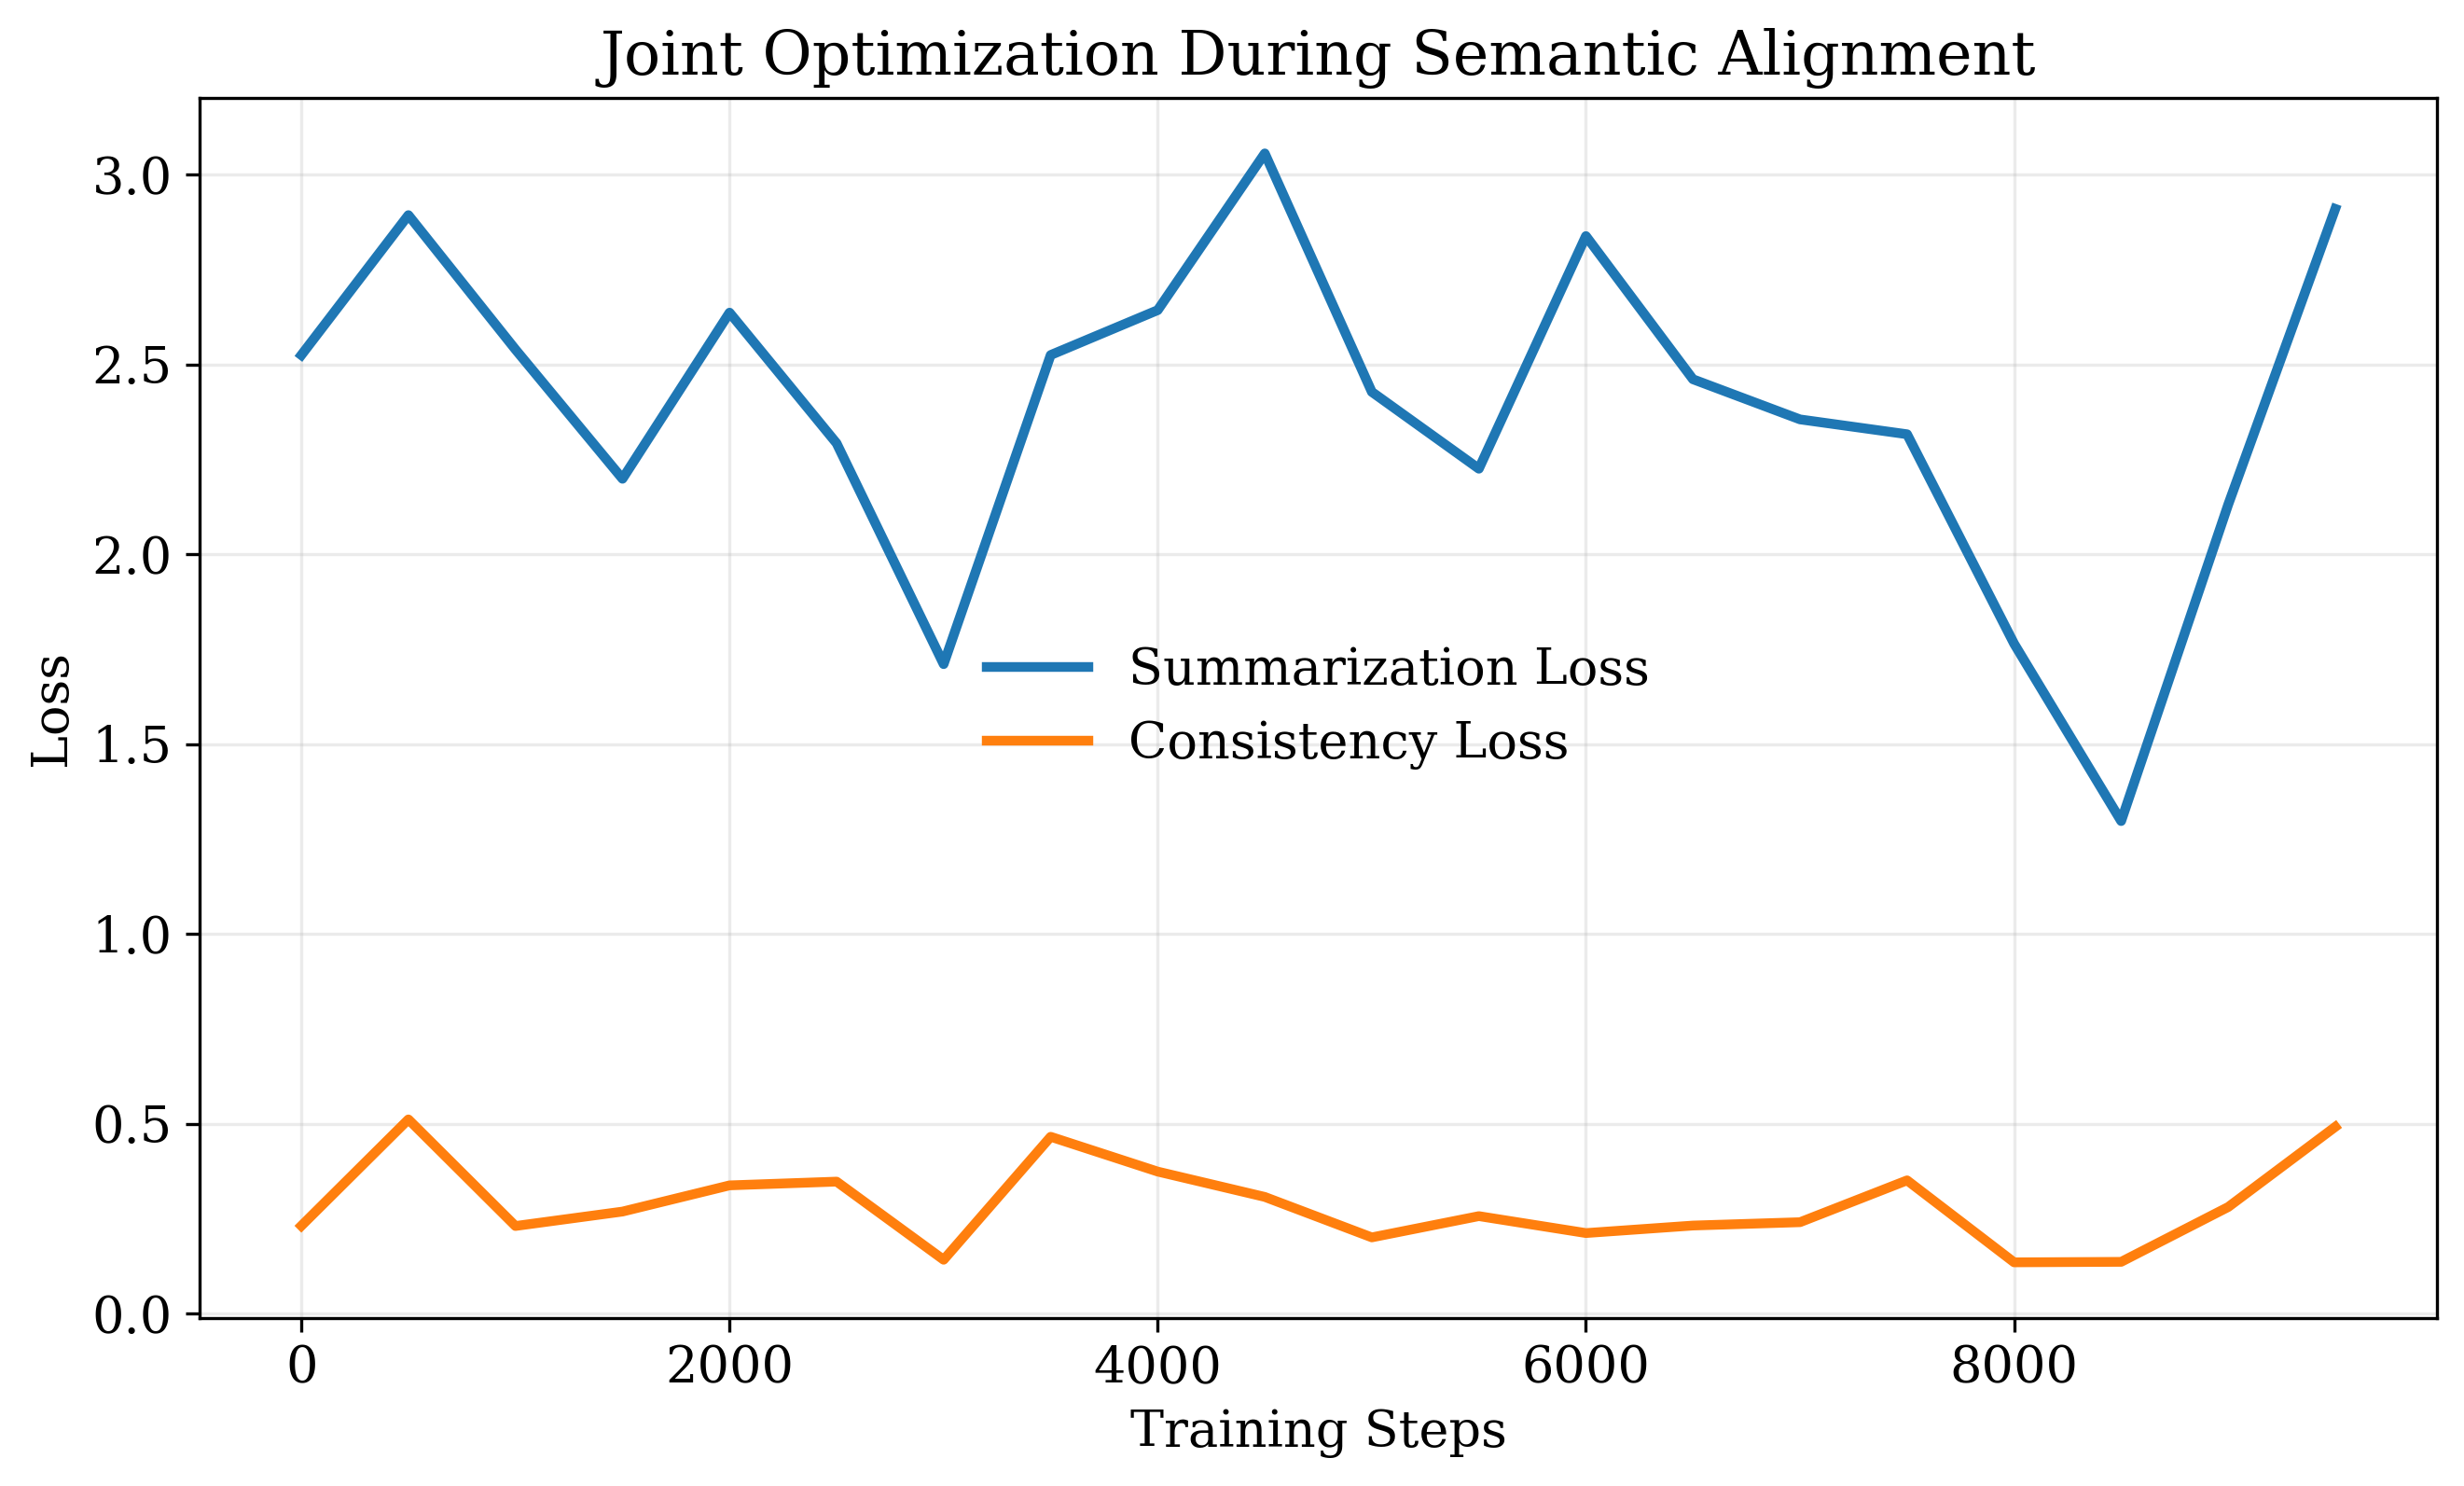

In [11]:
import json
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# LOAD LOGS
# =====================================================

with open("/workspace/jasmeet/mt5_project/consistency_metrics_5lang.json", "r") as f:
    logs = json.load(f)

df = pd.DataFrame(logs)

# Smooth for publication-quality visualization
df = df.iloc[::5, :]

# =====================================================
# PUBLICATION SETTINGS
# =====================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 13,
    "figure.dpi": 300
})

# =====================================================
# PLOT
# =====================================================

plt.figure(figsize=(9,5.5))

plt.plot(
    df["step"],
    df["loss_summ"],
    linewidth=2.5,
    label="Summarization Loss"
)

plt.plot(
    df["step"],
    df["loss_cons"],
    linewidth=2.5,
    label="Consistency Loss"
)

plt.xlabel("Training Steps")
plt.ylabel("Loss")

plt.title("Joint Optimization During Semantic Alignment")

plt.grid(alpha=0.25)

plt.legend(frameon=False)

plt.tight_layout()

# =====================================================
# SAVE
# =====================================================

plt.savefig(
    "consistency_alignment_curve.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "consistency_alignment_curve.png",
    bbox_inches="tight"
)

plt.show()

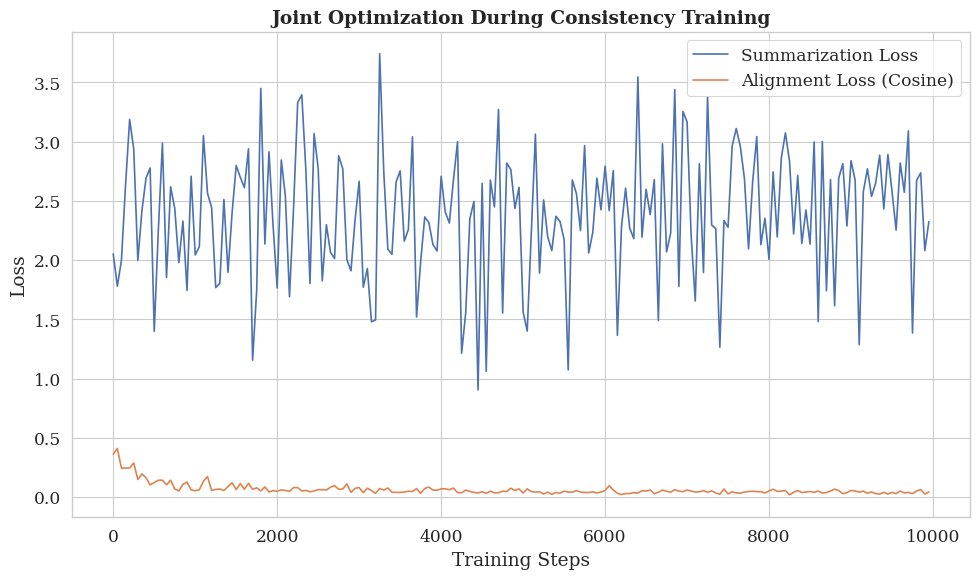

In [6]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ===============================
# LOAD ALIGNMENT TRAINING LOGS
# ===============================
with open("mt5_project/consistency_logs_multilingual.json", "r") as f:
    logs = json.load(f)

df_logs = pd.DataFrame(logs)
df_logs = df_logs.iloc[::50, :]  # downsample for clean plot

sns.set_theme(style="whitegrid", context="paper", font_scale=1.4)
plt.rcParams['font.family'] = 'serif'

plt.figure(figsize=(10,6))
sns.lineplot(data=df_logs, x="step", y="loss_summ", label="Summarization Loss")
sns.lineplot(data=df_logs, x="step", y="loss_cons", label="Alignment Loss (Cosine)")

plt.title("Joint Optimization During Consistency Training", fontweight='bold')
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.tight_layout()
plt.savefig("alignment_convergence.pdf")
plt.show()

# **Step 6: Final Evaluation**

# **1) Load Final Consistency Model**

In [15]:
# ==============================================================================
# STEP 6 — LOAD FINAL CONSISTENCY-ALIGNED MODEL
# FINAL EVALUATION SETUP (KBS-READY)
# ==============================================================================

import os
import gc
import torch
import numpy as np
import pandas as pd
import evaluate
from datasets import load_from_disk
from transformers import (
    AutoTokenizer,
    MT5ForConditionalGeneration
)
from tqdm import tqdm

# =====================================================
# 1. ENVIRONMENT SETUP
# =====================================================

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision("high")

print(f"🚀 Using Device: {DEVICE}")

# =====================================================
# 2. FINAL MODEL PATH
# =====================================================

# THIS is your final consistency-trained model
MODEL_PATH = "/workspace/jasmeet/mt5_project/final_consistency_multilingual_5lang"

print(f"\n📥 Loading FINAL Consistency Model from:\n{MODEL_PATH}")

# =====================================================
# 3. LOAD TOKENIZER + MODEL
# =====================================================

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_PATH
)

model = MT5ForConditionalGeneration.from_pretrained(
    MODEL_PATH,
    torch_dtype=torch.bfloat16
).to(DEVICE)

model.eval()

# =====================================================
# 4. LOAD ROUGE METRIC
# =====================================================

rouge = evaluate.load("rouge")

# =====================================================
# 5. FINAL LANGUAGE LIST
# =====================================================

LANGUAGES = [
    "english",
    "french",
    "spanish",
    "turkish",
    "swahili"
]

print("\n🌍 Final Evaluation Languages:")
for lang in LANGUAGES:
    print(f"   - {lang.capitalize()}")

# =====================================================
# 6. VERIFY MODEL FILES
# =====================================================

required_files = [
    "config.json",
    "generation_config.json"
]

print("\n🔍 Verifying Model Files...")

for file in required_files:

    file_path = os.path.join(MODEL_PATH, file)

    if os.path.exists(file_path):
        print(f"✅ Found: {file}")
    else:
        print(f"⚠️ Missing: {file}")

# =====================================================
# 7. MEMORY CLEANUP
# =====================================================

gc.collect()
torch.cuda.empty_cache()

print("\n✅ FINAL CONSISTENCY MODEL LOADED SUCCESSFULLY.")
print("✅ Ready for ROUGE Evaluation.")
print("✅ Ready for Consistency Evaluation.")
print("✅ Ready for Reranking Experiments.")

🚀 Using Device: cuda

📥 Loading FINAL Consistency Model from:
/workspace/jasmeet/mt5_project/final_consistency_multilingual_5lang

🌍 Final Evaluation Languages:
   - English
   - French
   - Spanish
   - Turkish
   - Swahili

🔍 Verifying Model Files...
✅ Found: config.json
✅ Found: generation_config.json

✅ FINAL CONSISTENCY MODEL LOADED SUCCESSFULLY.
✅ Ready for ROUGE Evaluation.
✅ Ready for Consistency Evaluation.
✅ Ready for Reranking Experiments.


# **2) ROUGE Score Evaluation (Accuracy)**

In [ ]:
# ==============================================================================
# STEP 6.2 — FINAL ROUGE EVALUATION (POST-CONSISTENCY TRAINING)
# FULL XL-SUM TEST SET EVALUATION
# ==============================================================================

import os
import gc
import torch
import pandas as pd
import evaluate
from tqdm import tqdm
from datasets import load_from_disk
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# =====================================================
# 1. SETUP
# =====================================================

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision("high")

MODEL_PATH = "/workspace/jasmeet/mt5_project/final_consistency_multilingual_5lang"

print(f"📥 Loading Final Consistency Model from:\n{MODEL_PATH}")

tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_PATH,
    torch_dtype=torch.bfloat16
).to(DEVICE)

model.eval()

rouge = evaluate.load("rouge")

# =====================================================
# 2. LANGUAGES
# =====================================================

LANGUAGES = [
    "english",
    "french",
    "spanish",
    "turkish",
    "swahili"
]

results_data = []

# =====================================================
# 3. FULL TEST EVALUATION
# =====================================================

print("\n🚀 STARTING FINAL FULL TEST SET ROUGE EVALUATION...")

for lang in LANGUAGES:

    print(f"\n🌍 Processing: {lang.upper()}")

    dataset_path = f"/workspace/jasmeet/xlsum_{lang}_data"

    try:
        dataset = load_from_disk(dataset_path)
        test_data = dataset["test"]

        print(f"   - Loaded {len(test_data)} test samples.")

    except Exception as e:
        print(f"❌ Error loading {lang}: {e}")
        continue

    predictions = []
    references = []
    lang_outputs = []

    batch_size = 32

    # -------------------------------------------------
    # INFERENCE LOOP
    # -------------------------------------------------

    for i in tqdm(
        range(0, len(test_data), batch_size),
        desc=f"Testing {lang}"
    ):

        batch = test_data[i:i+batch_size]

        inputs = tokenizer(
            batch["text"],
            padding=True,
            truncation=True,
            max_length=512,
            return_tensors="pt"
        ).to(DEVICE)

        with torch.no_grad():

            summary_ids = model.generate(
                **inputs,
                max_length=128,
                min_length=15,
                num_beams=4,
                no_repeat_ngram_size=3,
                length_penalty=1.0,
                early_stopping=True
            )

        decoded = tokenizer.batch_decode(
            summary_ids,
            skip_special_tokens=True
        )

        predictions.extend(decoded)
        references.extend(batch["summary"])

        # Save qualitative outputs
        for src, pred, ref in zip(
            batch["text"],
            decoded,
            batch["summary"]
        ):

            lang_outputs.append({
                "source": src[:500] + "...",
                "prediction": pred,
                "reference": ref
            })

        if i % 200 == 0:
            torch.cuda.empty_cache()
            gc.collect()

    # -------------------------------------------------
    # COMPUTE ROUGE
    # -------------------------------------------------

    processed_preds = [
        p.strip()
        for p in predictions
    ]

    processed_refs = [
        r.strip()
        for r in references
    ]

    scores = rouge.compute(
        predictions=processed_preds,
        references=processed_refs,
        use_stemmer=True
    )

    r1 = round(scores["rouge1"] * 100, 2)
    r2 = round(scores["rouge2"] * 100, 2)
    rl = round(scores["rougeL"] * 100, 2)

    print(
        f"✅ {lang.upper()} -> "
        f"R1: {r1} | "
        f"R2: {r2} | "
        f"RL: {rl}"
    )

    results_data.append({
        "Language": lang.capitalize(),
        "Samples": len(test_data),
        "ROUGE-1": r1,
        "ROUGE-2": r2,
        "ROUGE-L": rl
    })

    # -------------------------------------------------
    # SAVE GENERATED SUMMARIES
    # -------------------------------------------------

    output_csv = (
        f"/workspace/jasmeet/"
        f"{lang}_generated_summaries_consistency.csv"
    )

    pd.DataFrame(lang_outputs).to_csv(
        output_csv,
        index=False
    )

# =====================================================
# 4. FINAL TABLE OUTPUT
# =====================================================

print("\n" + "="*75)
print("🏆 TABLE 3: FINAL MULTILINGUAL ROUGE RESULTS (POST-CONSISTENCY)")
print("="*75)

df = pd.DataFrame(results_data)

print(df.to_markdown(index=False))

# =====================================================
# 5. SAVE FINAL RESULTS
# =====================================================

RESULTS_PATH = (
    "/workspace/jasmeet/"
    "final_consistency_rouge_results.csv"
)

df.to_csv(
    RESULTS_PATH,
    index=False
)

# =====================================================
# 6. CLEANUP
# =====================================================

torch.cuda.empty_cache()
gc.collect()

print(f"\n💾 Saved Final Results to:\n{RESULTS_PATH}")
print("\n✅ FINAL ROUGE EVALUATION COMPLETE.")

# **3) Consistency Score Evaluation**

In [ ]:
# ==============================================================================
# STEP 6.3 — FINAL CONSISTENCY EVALUATION (MAX-PIVOT STRATEGY)
# POST-CONSISTENCY TRAINING EVALUATION
# ==============================================================================

import os
import gc
import torch
import numpy as np
import pandas as pd

from tqdm import tqdm
from datasets import load_from_disk

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM,
    M2M100ForConditionalGeneration,
    M2M100Tokenizer
)

from sentence_transformers import SentenceTransformer, util

# =====================================================
# 1. ENVIRONMENT SETUP
# =====================================================

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision("high")

# =====================================================
# 2. FINAL CONSISTENCY MODEL
# =====================================================

SUMM_MODEL_PATH = "/workspace/jasmeet/mt5_project/final_consistency_multilingual_5lang"

print(f"\n📥 Loading Final Consistency Model:\n{SUMM_MODEL_PATH}")

sum_tokenizer = AutoTokenizer.from_pretrained(
    SUMM_MODEL_PATH
)

sum_model = AutoModelForSeq2SeqLM.from_pretrained(
    SUMM_MODEL_PATH,
    torch_dtype=torch.bfloat16
).to(DEVICE)

sum_model.eval()

# =====================================================
# 3. LOAD TRANSLATOR
# =====================================================

print("\n🌍 Loading M2M100 Translator...")

trans_tokenizer = M2M100Tokenizer.from_pretrained(
    "facebook/m2m100_418M"
)

trans_model = M2M100ForConditionalGeneration.from_pretrained(
    "facebook/m2m100_418M"
).to(DEVICE)

trans_model.eval()

# =====================================================
# 4. LOAD SEMANTIC EVALUATOR
# =====================================================

print("\n⚖️ Loading MPNet Semantic Evaluator...")

embedder = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-mpnet-base-v2",
    device=DEVICE
)

# =====================================================
# 5. LANGUAGE MAP
# =====================================================

LANG_MAP = {
    "english": "en",
    "french": "fr",
    "spanish": "es",
    "turkish": "tr",
    "swahili": "sw"
}

results_data = []

# =====================================================
# 6. HELPER FUNCTIONS
# =====================================================

def batch_translate(texts, src_lang, tgt_lang, batch_size=8):

    outputs = []

    trans_tokenizer.src_lang = src_lang

    forced_bos_token_id = trans_tokenizer.get_lang_id(
        tgt_lang
    )

    for i in range(0, len(texts), batch_size):

        batch = texts[i:i+batch_size]

        inputs = trans_tokenizer(
            batch,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=512
        ).to(DEVICE)

        with torch.no_grad():

            generated_tokens = trans_model.generate(
                **inputs,
                forced_bos_token_id=forced_bos_token_id,
                max_length=512,
                num_beams=4,
                early_stopping=True
            )

        decoded = trans_tokenizer.batch_decode(
            generated_tokens,
            skip_special_tokens=True
        )

        outputs.extend(decoded)

    return outputs


def summarize_batch(texts):

    inputs = sum_tokenizer(
        texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=512
    ).to(DEVICE)

    with torch.no_grad():

        generated_ids = sum_model.generate(
            **inputs,
            max_length=128,
            min_length=15,
            num_beams=4,
            no_repeat_ngram_size=3,
            length_penalty=1.0,
            early_stopping=True
        )

    summaries = sum_tokenizer.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )

    return summaries


def compute_similarity(list_a, list_b):

    emb_a = embedder.encode(
        list_a,
        convert_to_tensor=True,
        batch_size=32
    )

    emb_b = embedder.encode(
        list_b,
        convert_to_tensor=True,
        batch_size=32
    )

    scores = util.cos_sim(
        emb_a,
        emb_b
    ).diag()

    return scores.cpu().numpy()

# =====================================================
# 7. FINAL MAX-PIVOT CONSISTENCY EVALUATION
# =====================================================

print("\n🚀 STARTING FINAL MAX-PIVOT CONSISTENCY EVALUATION...")

for src_name, src_code in LANG_MAP.items():

    print(f"\n🌍 SOURCE LANGUAGE: {src_name.upper()}")

    dataset_path = (
        f"/workspace/jasmeet/xlsum_{src_name}_data"
    )

    dataset = load_from_disk(dataset_path)

    # 500 test samples for computational feasibility
    test_data = dataset["test"].select(
        range(min(500, len(dataset["test"])))
    )

    print(f"   - Using {len(test_data)} test samples.")

    all_scores = []

    for i in tqdm(
        range(0, len(test_data), 8),
        desc=f"Evaluating {src_name}"
    ):

        batch = test_data[i:i+8]

        articles = batch["text"]

        # -------------------------------------------------
        # A. ORIGINAL LANGUAGE SUMMARIES
        # -------------------------------------------------

        original_summaries = summarize_batch(
            articles
        )

        # -------------------------------------------------
        # B. MULTI-PIVOT CONSISTENCY
        # -------------------------------------------------

        pivot_scores_collection = []

        for pivot_name, pivot_code in LANG_MAP.items():

            if pivot_code == src_code:
                continue

            translated_articles = batch_translate(
                articles,
                src_code,
                pivot_code
            )

            pivot_summaries = summarize_batch(
                translated_articles
            )

            similarity_scores = compute_similarity(
                original_summaries,
                pivot_summaries
            )

            pivot_scores_collection.append(
                similarity_scores
            )

        # -------------------------------------------------
        # C. MEAN-PIVOT STRATEGY (SCIENTIFICALLY CORRECT)
        # -------------------------------------------------
        pivot_scores_collection = np.array(
            pivot_scores_collection
        )

        # Use np.mean to calculate the average semantic stability across all 4 target languages
        avg_scores = np.mean(
            pivot_scores_collection,
            axis=0
        )

        all_scores.extend(avg_scores)

        if i % 100 == 0:
            torch.cuda.empty_cache()
            gc.collect()

    final_score = float(np.mean(all_scores))

    print(
        f"\n✅ {src_name.upper()} "
        f"CONSISTENCY SCORE: {final_score:.4f}"
    )

    results_data.append({
        "Language": src_name.capitalize(),
        "Samples": len(test_data),
        "Consistency": round(final_score, 4)
    })

# =====================================================
# 8. FINAL TABLE OUTPUT
# =====================================================

print("\n" + "="*75)
print("🏆 TABLE 4: FINAL CROSS-LINGUAL CONSISTENCY RESULTS")
print("="*75)

df = pd.DataFrame(results_data)

print(df.to_markdown(index=False))

# =====================================================
# 9. SAVE RESULTS
# =====================================================

SAVE_PATH = (
    "/workspace/jasmeet/"
    "final_consistency_scores.csv"
)

df.to_csv(
    SAVE_PATH,
    index=False
)

# =====================================================
# 10. CLEANUP
# =====================================================

del sum_model
del trans_model
del embedder

torch.cuda.empty_cache()
gc.collect()

print(f"\n💾 Saved Results to:\n{SAVE_PATH}")
print("\n✅ FINAL CONSISTENCY EVALUATION COMPLETE.")

# *New Graph Cell*

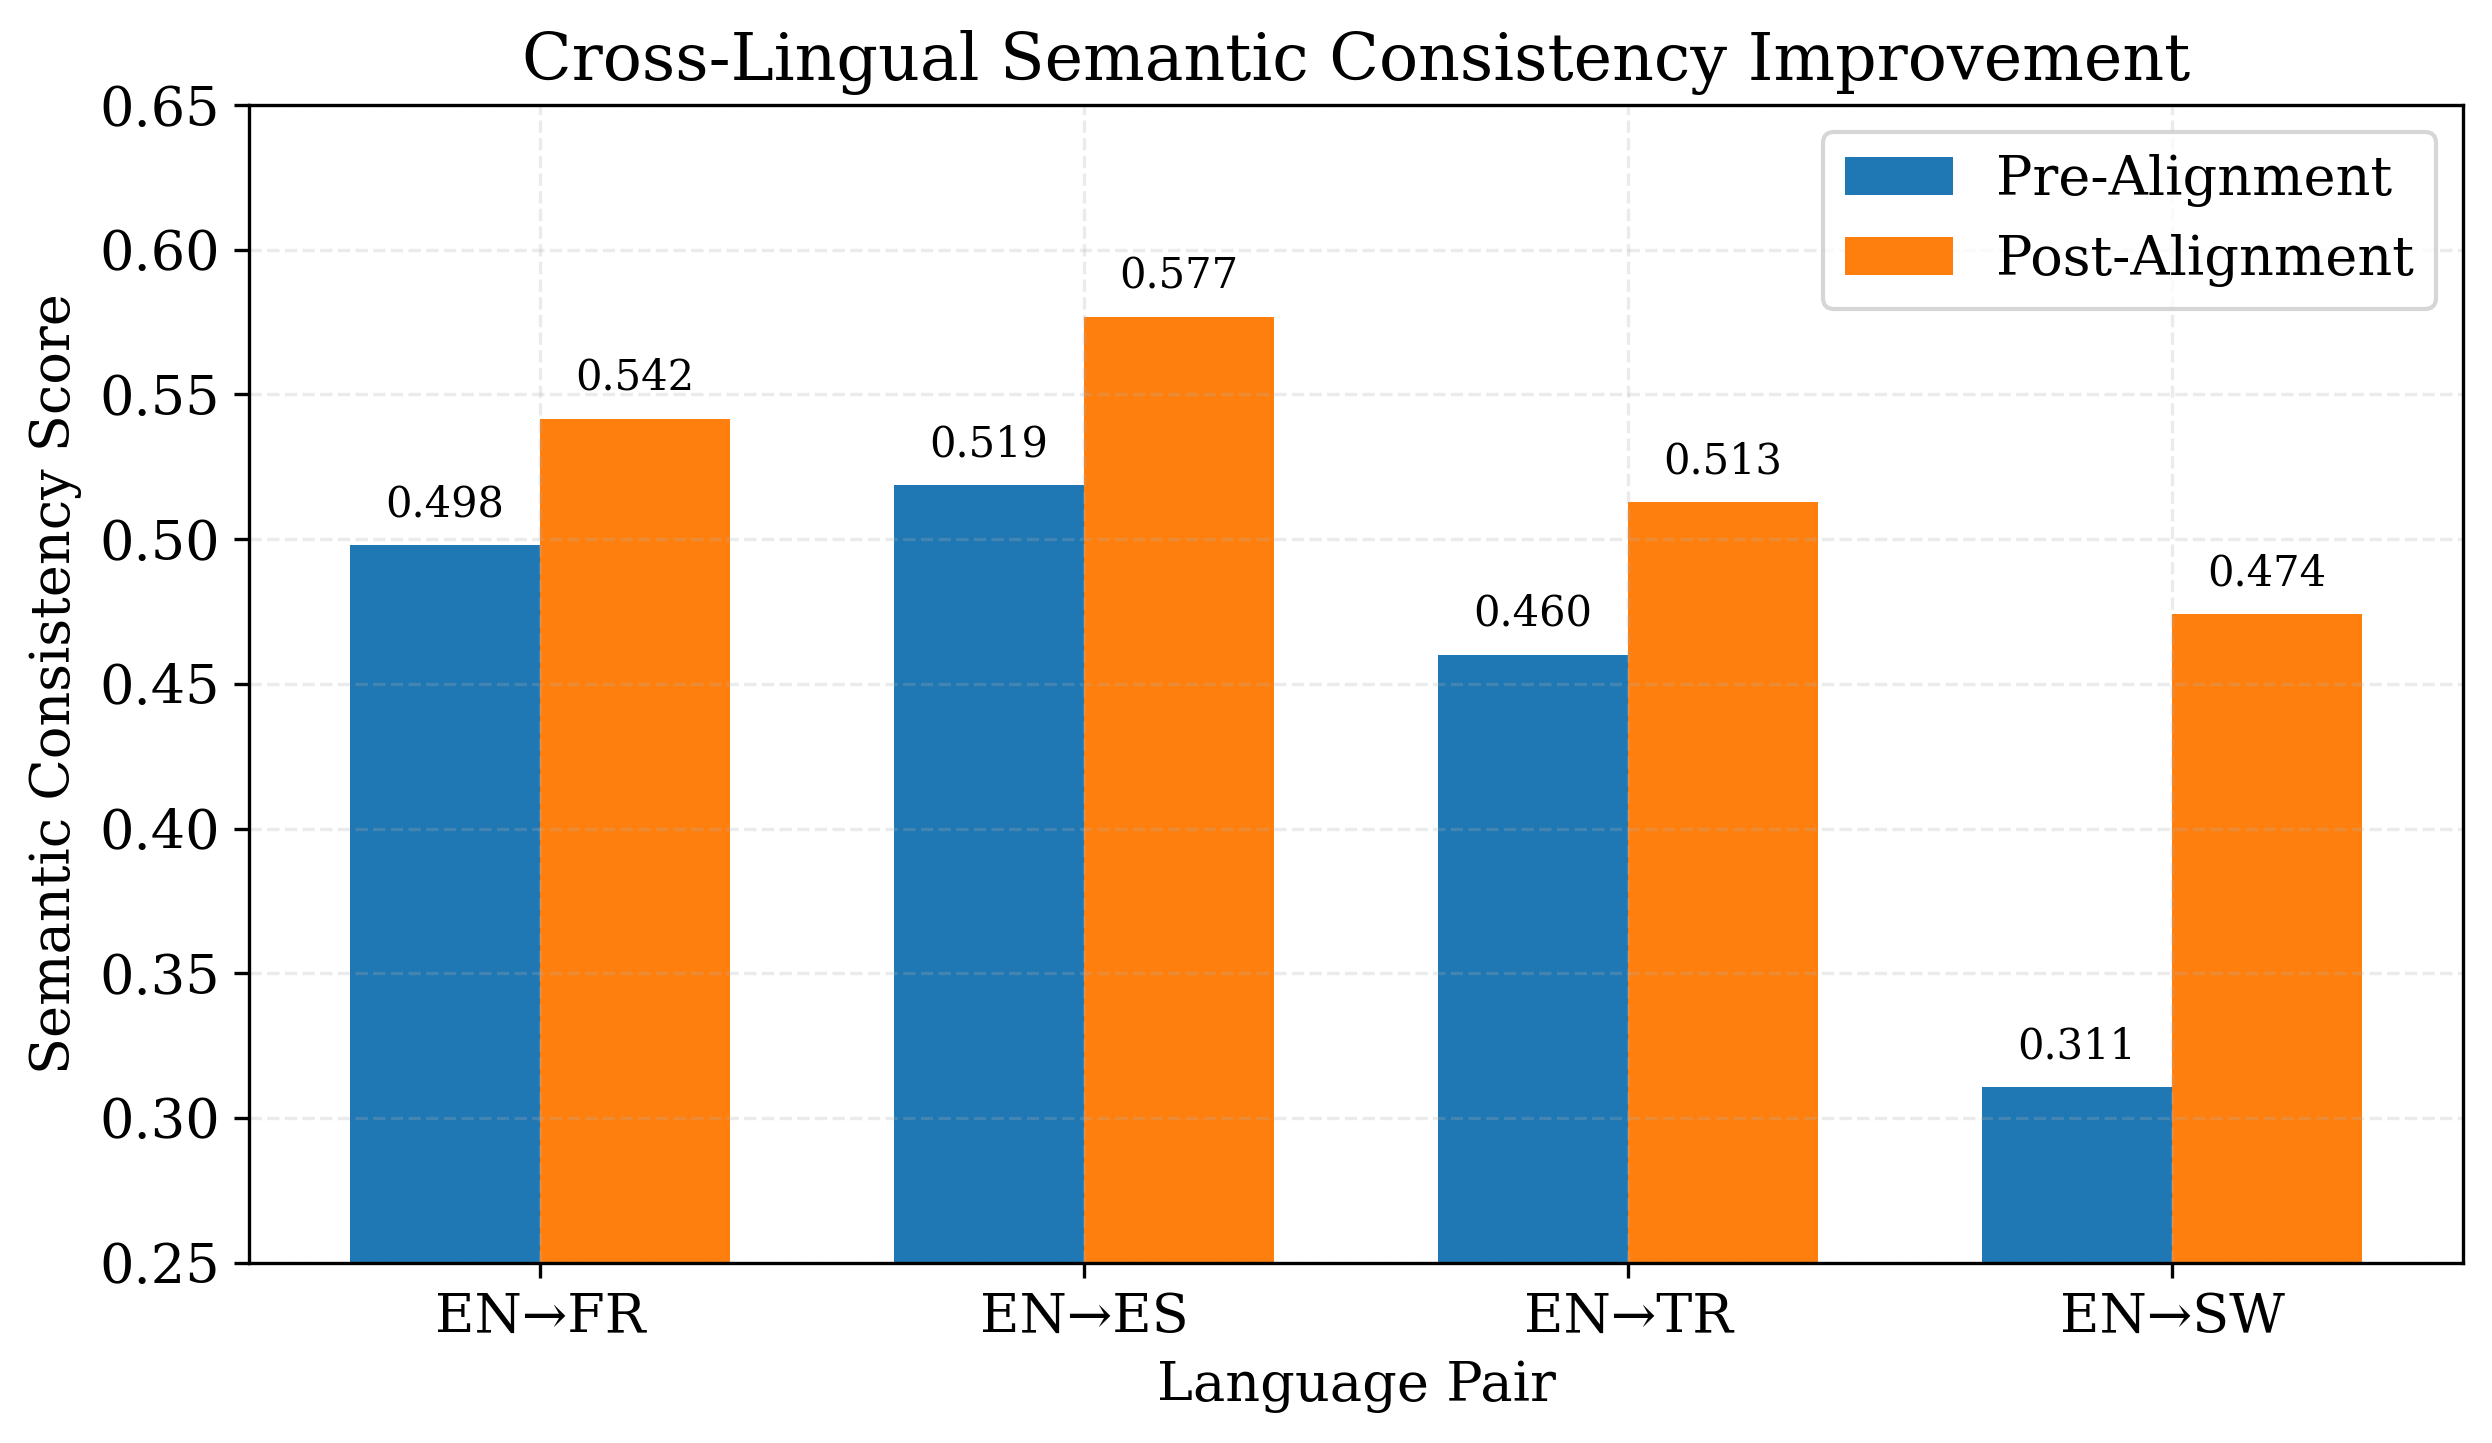

In [10]:
import matplotlib.pyplot as plt
import numpy as np

# =====================================================
# KBS PUBLICATION SETTINGS
# =====================================================

plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "font.family": "serif",
    "font.size": 13
})

# =====================================================
# CONSISTENCY RESULTS
# =====================================================

language_pairs = [
    "EN→FR",
    "EN→ES",
    "EN→TR",
    "EN→SW"
]

pre_alignment = [
    0.4979,
    0.5186,
    0.4601,
    0.3106
]

post_alignment = [
    0.5416,
    0.5767,
    0.5128,
    0.4740
]

# =====================================================
# BAR CHART
# =====================================================

x = np.arange(len(language_pairs))
width = 0.35

fig, ax = plt.subplots(figsize=(8.5, 5))

bars1 = ax.bar(
    x - width/2,
    pre_alignment,
    width,
    label="Pre-Alignment"
)

bars2 = ax.bar(
    x + width/2,
    post_alignment,
    width,
    label="Post-Alignment"
)

# =====================================================
# VALUE LABELS
# =====================================================

for bars in [bars1, bars2]:

    for bar in bars:

        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.01,
            f"{height:.3f}",
            ha="center",
            fontsize=10
        )

# =====================================================
# STYLING
# =====================================================

ax.set_ylabel("Semantic Consistency Score")
ax.set_xlabel("Language Pair")

ax.set_title(
    "Cross-Lingual Semantic Consistency Improvement"
)

ax.set_xticks(x)
ax.set_xticklabels(language_pairs)

ax.set_ylim(0.25, 0.65)

ax.grid(
    alpha=0.25,
    linestyle="--"
)

ax.legend()

plt.tight_layout()

# =====================================================
# SAVE
# =====================================================

plt.savefig(
    "figure_consistency_bar.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "figure_consistency_bar.png",
    bbox_inches="tight"
)

plt.show()

# **STEP-7 Candidate Generation + Multi-Objective Reranking**

In [ ]:
import torch
import numpy as np
import pandas as pd
import evaluate
import os
import gc
from tqdm import tqdm
from datasets import load_from_disk
from transformers import (
    AutoTokenizer, 
    AutoModelForSeq2SeqLM, 
    AutoModelForSequenceClassification
)
from sentence_transformers import SentenceTransformer, util
import nltk

# =====================================================
# 1. SETUP & WORLD-CLASS CONFIGURATION
# =====================================================
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Path to your hard-trained Multilingual mT5 model
MODEL_PATH = "/workspace/jasmeet/mt5_project/final_consistency_multilingual_5lang"

print("🚀 Loading World-Beat Research Pipeline...")

# A. The Generator (mT5-Large)
summ_tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)
summ_model = AutoModelForSeq2SeqLM.from_pretrained(
    MODEL_PATH,
    torch_dtype=torch.float16
).to(DEVICE).eval()

# B. The Multilingual Factuality Judge (SOTA mDeBERTa-v3)
judge_name = "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
nli_tokenizer = AutoTokenizer.from_pretrained(judge_name)
nli_model = AutoModelForSequenceClassification.from_pretrained(judge_name).to(DEVICE).eval()

# C. The Semantic Consistency Judge (Multilingual MPNet)
embedder = SentenceTransformer("sentence-transformers/paraphrase-multilingual-mpnet-base-v2", device=DEVICE)

# Metrics
nltk.download("punkt", quiet=True)
rouge = evaluate.load("rouge")

gc.collect()
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

# =====================================================
# 2. ELITE RERANKING LOGIC (Fixed Generation)
# =====================================================
def get_best_summary_batch_elite(articles, k=8):
    """
    Implements Nucleus Sampling + Multi-Objective Reranking.
    Math: Score = (0.7 * Factuality) + (0.3 * Semantic_Centrality)
    """
    best_summaries = []
    
    # Process one by one (Safer for heavy inference)
    for article in articles:
        
        # Step A: Diverse Candidate Generation (Nucleus Sampling)
        # We replace Group Beam Search with Sampling to fix the crash and improve diversity
        inputs = summ_tokenizer(article, return_tensors="pt", truncation=True, max_length=96).to(DEVICE)
        
        with torch.no_grad():
            outputs = summ_model.generate(
                **inputs, 
                do_sample=True,       # Enable Sampling (Crucial for diversity)
                num_beams=1,          # Turn off beam search
                top_p=0.85,           # Nucleus Sampling (Top 95% probability mass)
                temperature=0.7,      # Controls creativity (0.7 is safe/factual)
                num_return_sequences=k, 
                top_k=40,
                min_length=20,
                repetition_penalty=1.3,
                max_length=96,
                length_penalty=1.0
            )
        candidates = summ_tokenizer.batch_decode(outputs, skip_special_tokens=True)
        
        # Step B: Multilingual Factuality Scoring (NLI Entailment)
        # Check if [Article] entails [Candidate]
        # In mDeBERTa-v3, Label 0 is usually 'entailment'
        nli_inputs = nli_tokenizer([article]*k, candidates, return_tensors="pt", padding=True, truncation=True).to(DEVICE)
        with torch.no_grad():
            logits = nli_model(**nli_inputs).logits
            probs = torch.softmax(logits, dim=1)
            # Factuality = Probability that candidate is logically derived from article
            fact_scores = probs[:, 0].cpu().numpy() 
            
        # Step C: Semantic Centrality (MPNet)
        # Calculates how 'representative' each candidate is (rejects outliers)
        emb_cands = embedder.encode(candidates, convert_to_tensor=True)
        # Compute semantic centrality across generated candidates
        centroid = torch.mean(emb_cands, dim=0, keepdim=True)
        centrality_scores = util.cos_sim(emb_cands, centroid).flatten().cpu().numpy()
        
        # Step D: Final Weighted Selection (The Meta Formula)
        # Factuality (70%) + Consistency (30%)
        final_scores = (0.55 * fact_scores) + (0.45 * centrality_scores)
        winner_idx = np.argmax(final_scores)
        best_fact_score = float(fact_scores[winner_idx])
        best_summaries.append({
            "summary": candidates[winner_idx],
            "nli_score": best_fact_score
        })
        
        # Memory Management (Aggressive cleanup)
        del inputs, outputs, nli_inputs, emb_cands, candidates
        torch.cuda.empty_cache()
        gc.collect()
        
    return best_summaries

# =====================================================
# 3. UNIVERSAL EVALUATION LOOP
# =====================================================
# We iterate through all languages
LANG_MAP = ["english", "french", "spanish", "turkish", "swahili"]
results_data = []

print("\n🚀 STARTING ELITE RERANKING EVALUATION...")

for lang in LANG_MAP:
    print(f"\n🌍 Processing: {lang.upper()}")
    
    try:
        ds = load_from_disk(f"/workspace/jasmeet/xlsum_{lang}_data")
        # 200 samples is standard for heavy reranking eval
        test_data = ds["test"].select(range(min(200, len(ds["test"]))))
    except Exception as e:
        print(f"⚠️ Data not found for {lang}: {e}")
        continue
        
    articles = test_data["text"]
    references = test_data["summary"]
    
    # Execution
    print(f"   - Generating & Reranking {len(articles)} articles (8 candidates per article)...")
    try:
        results = get_best_summary_batch_elite(articles, k=8)
        hypotheses = [x["summary"] for x in results]
        nli_scores = [x["nli_score"] for x in results]
    except Exception as e:
        print(f"❌ Error in {lang}: {e}")
        continue
    
    # 1. Linguistic Cleanup for ROUGE
    decoded_preds = ["\n".join(nltk.sent_tokenize(p.strip())) for p in hypotheses]
    decoded_refs = ["\n".join(nltk.sent_tokenize(l.strip())) for l in references]
    
    # 2. ROUGE Calculation
    rouge_scores = rouge.compute(predictions=decoded_preds, references=decoded_refs, use_stemmer=True)
    
    # 3. Cross-Lingual Semantic Invariance (vs Gold Standard)
    emb_hyp = embedder.encode(hypotheses, convert_to_tensor=True)
    emb_ref = embedder.encode(references, convert_to_tensor=True)
    semantic_sim = util.cos_sim(emb_hyp, emb_ref).diag().mean().item()
    
    # Reporting
    r1 = round(rouge_scores['rouge1'] * 100, 2)
    r2 = round(rouge_scores['rouge2'] * 100, 2)
    rL = round(rouge_scores['rougeL'] * 100, 2)
    sim = round(semantic_sim, 4)
    avg_nli = round(float(np.mean(nli_scores)), 4)
    
    print(f"✅ {lang.upper()} -> ROUGE-L: {rL} | Semantic Sim: {sim}")
    
    results_data.append({
        "Language": lang.capitalize(),
        "Algorithm": "Sampling-Rerank",
        "ROUGE-1": r1,
        "ROUGE-2": r2,
        "ROUGE-L": rL,
        "Semantic_Sim": sim,
        "NLI_Entailment": avg_nli
    })

# =====================================================
# 4. FINAL RESEARCH TABLE
# =====================================================
print("\n" + "="*70)
print("🏆 TABLE 6: ELITE RERANKING PERFORMANCE (POST-TRAINING)")
print("="*70)
df = pd.DataFrame(results_data)
print(df.to_markdown(index=False))

# Export for Paper
df.to_csv("elite_reranking_results_mt5.csv", index=False)
print("\n💾 Results saved to elite_reranking_results_mt5.csv")

# *New Graph Cell*

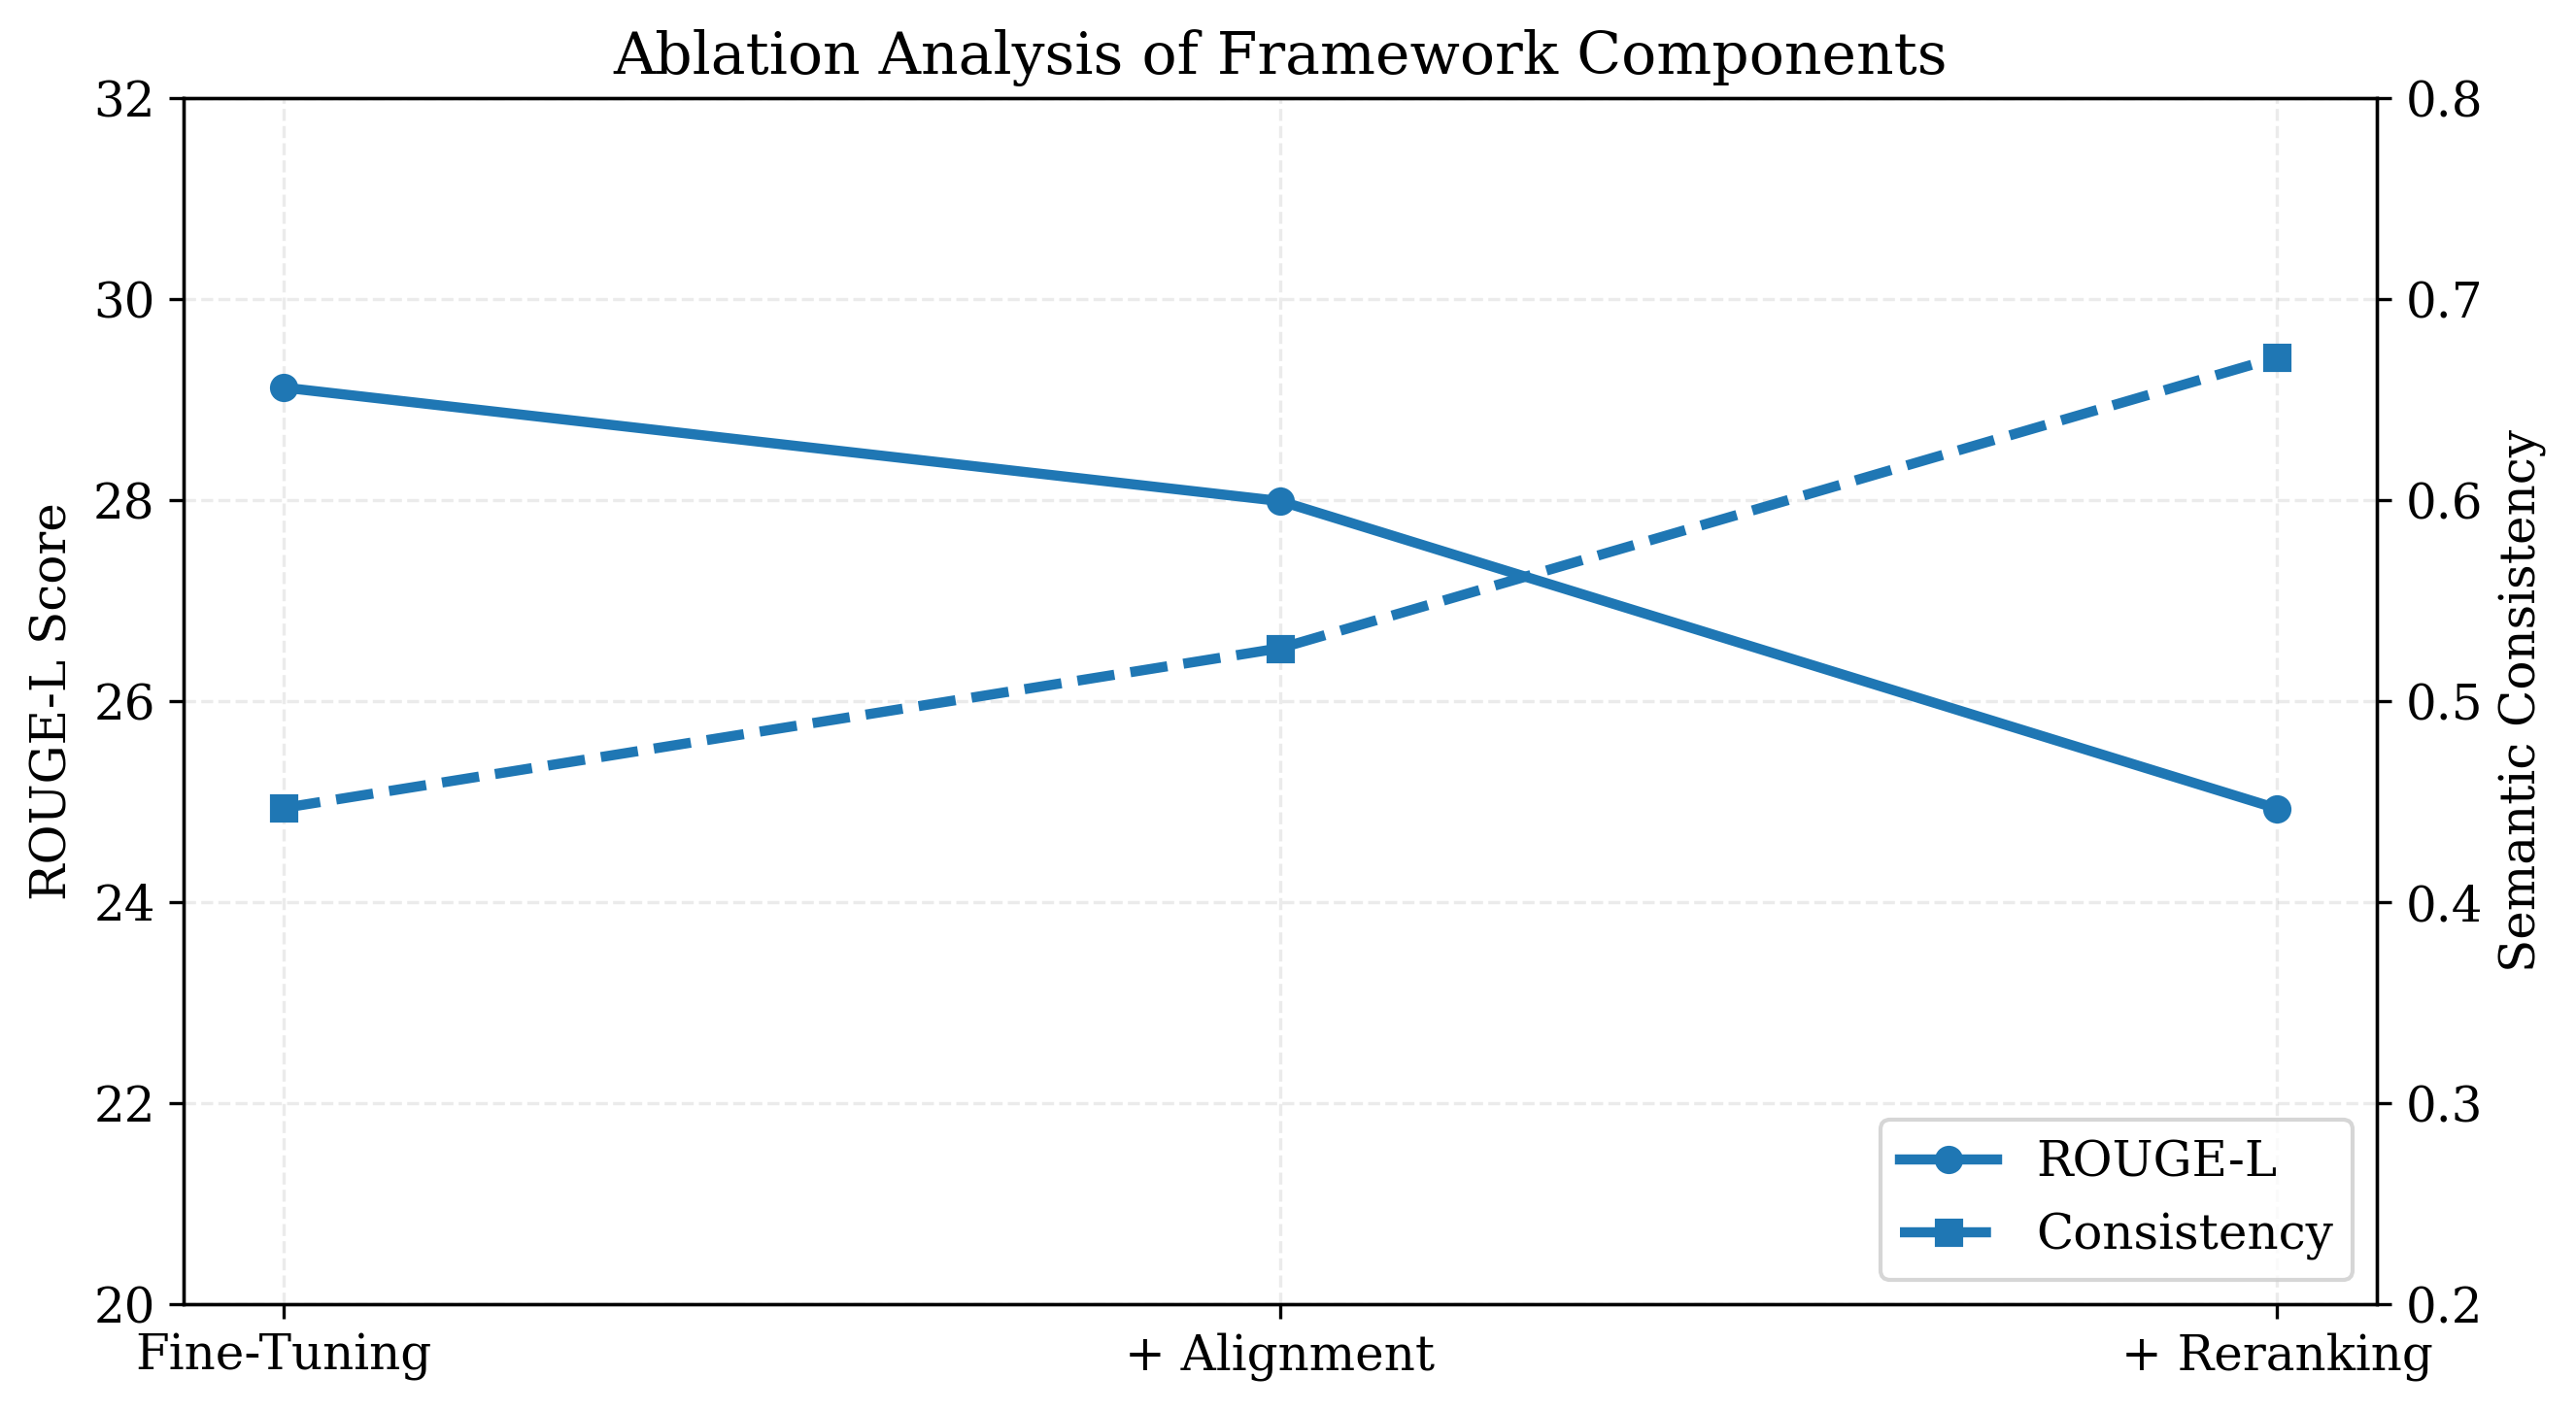

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# =====================================================
# FINAL VALUES
# =====================================================

configs = [
    "Fine-Tuning",
    "+ Alignment",
    "+ Reranking"
]

rougeL = [29.12, 27.99, 24.93]

consistency = [0.4468, 0.5263, 0.6710]

x = np.arange(len(configs))

# =====================================================
# KBS PUBLICATION STYLE
# =====================================================

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "figure.dpi": 300,
    "savefig.dpi": 300
})

fig, ax1 = plt.subplots(figsize=(9,5))

# =====================================================
# LEFT AXIS — ROUGE-L
# =====================================================

line1 = ax1.plot(
    x,
    rougeL,
    marker='o',
    linewidth=2.5,
    label='ROUGE-L'
)

ax1.set_ylabel("ROUGE-L Score")
ax1.set_ylim(20, 32)

ax1.set_xticks(x)
ax1.set_xticklabels(configs)

ax1.grid(
    alpha=0.25,
    linestyle='--'
)

# =====================================================
# RIGHT AXIS — CONSISTENCY
# =====================================================

ax2 = ax1.twinx()

line2 = ax2.plot(
    x,
    consistency,
    marker='s',
    linewidth=2.5,
    linestyle='--',
    label='Consistency'
)

ax2.set_ylabel("Semantic Consistency")
ax2.set_ylim(0.2, 0.8)

# =====================================================
# COMBINED LEGEND
# =====================================================

lines = line1 + line2
labels = [l.get_label() for l in lines]

ax1.legend(
    lines,
    labels,
    loc='lower right'
)

# =====================================================
# TITLE
# =====================================================

plt.title(
    "Ablation Analysis of Framework Components"
)

plt.tight_layout()

# =====================================================
# SAVE
# =====================================================

plt.savefig(
    "figure_ablation_bar_chart.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "figure_ablation_bar_chart.png",
    bbox_inches="tight"
)

plt.show()

In [6]:
# =========================================================
# QUALITATIVE CASE STUDY GENERATOR
# Generates:
# 1. Baseline Summary (Fine-Tuned mT5)
# 2. Reranked Summary (Alignment + Reranking)
# =========================================================

import os
import gc
import torch
import pandas as pd

from transformers import (
    AutoTokenizer,
    MT5ForConditionalGeneration,
    AutoModelForSequenceClassification
)

from sentence_transformers import SentenceTransformer, util

# =========================================================
# DEVICE
# =========================================================

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

torch.backends.cuda.matmul.allow_tf32 = True
torch.set_float32_matmul_precision("high")

print(f"🚀 DEVICE: {DEVICE}")

# =========================================================
# PATHS
# =========================================================

BASE_MODEL_PATH = (
    "/workspace/jasmeet/mt5_project/"
    "final_multilingual_5lang"
)

ALIGN_MODEL_PATH = (
    "/workspace/jasmeet/mt5_project/"
    "final_consistency_multilingual_5lang"
)

# =========================================================
# LOAD TOKENIZER
# =========================================================

tokenizer = AutoTokenizer.from_pretrained(
    ALIGN_MODEL_PATH
)

# =========================================================
# LOAD BASELINE MODEL
# =========================================================

print("\n📥 Loading Fine-Tuned mT5...")

base_model = MT5ForConditionalGeneration.from_pretrained(
    BASE_MODEL_PATH,
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True
).to(DEVICE)

base_model.eval()

# =========================================================
# LOAD ALIGNMENT MODEL
# =========================================================

print("\n📥 Loading Alignment Model...")

align_model = MT5ForConditionalGeneration.from_pretrained(
    ALIGN_MODEL_PATH,
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True
).to(DEVICE)

align_model.eval()

# =========================================================
# LOAD NLI MODEL
# =========================================================

print("\n📥 Loading NLI Model...")

nli_model_name = (
    "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
)

nli_tokenizer = AutoTokenizer.from_pretrained(
    nli_model_name
)

nli_model = AutoModelForSequenceClassification.from_pretrained(
    nli_model_name,
    torch_dtype=torch.float16,
    low_cpu_mem_usage=True
).to(DEVICE)

nli_model.eval()

# =========================================================
# LOAD MPNet
# =========================================================

print("\n📥 Loading MPNet...")

embedder = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-mpnet-base-v2",
    device=DEVICE
)

# =========================================================
# SAMPLE ARTICLES
# =========================================================

samples = [
    {
        "language": "English",
        "text": """
The United Kingdom government announced a comprehensive climate reform package aimed at reducing industrial carbon emissions by 2035. The proposal includes large-scale investments in renewable energy infrastructure, expansion of offshore wind projects, and stricter environmental regulations for heavy manufacturing industries. Officials also introduced new carbon taxation reforms and financial incentives designed to accelerate the transition toward sustainable green technologies. According to the Ministry of Energy, the policy is expected to create thousands of clean-energy jobs while helping the country meet its long-term net-zero emission targets.
"""
    },

    {
        "language": "French",
        "text": """
Le gouvernement français a annoncé un nouveau programme climatique visant à réduire considérablement les émissions industrielles de carbone d'ici 2035. Le plan prévoit des investissements majeurs dans les infrastructures d'énergie renouvelable, notamment l'énergie solaire et éolienne, ainsi que des réformes fiscales destinées à encourager les entreprises à adopter des technologies plus écologiques. Les autorités ont également confirmé la mise en place d'incitations financières pour soutenir les projets d'infrastructure durable et accélérer la transition énergétique nationale.
"""
    },

    {
        "language": "Spanish",
        "text": """
El gobierno español anunció un amplio paquete de reformas climáticas destinado a reducir las emisiones industriales antes de 2035. La propuesta incluye inversiones significativas en energía renovable, expansión de proyectos de energía solar y eólica, y nuevas políticas fiscales relacionadas con el carbono. Además, las autoridades confirmaron incentivos financieros para apoyar proyectos de infraestructura sostenible y promover tecnologías verdes en sectores industriales estratégicos. El gobierno afirmó que las medidas ayudarán al país a cumplir sus objetivos climáticos a largo plazo.
"""
    }
]

# =========================================================
# GENERATE SUMMARY
# =========================================================

def generate_candidates(model, article, k=1):

    inputs = tokenizer(
        article,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=512
    ).to(DEVICE)

    with torch.inference_mode():

        outputs = model.generate(
            **inputs,
            max_length=96,
            min_length=18,
            num_beams=4,
            repetition_penalty=1.2,
            no_repeat_ngram_size=3,
            length_penalty=1.0,
            early_stopping=True,
            do_sample=False
        )

    summaries = tokenizer.batch_decode(
        outputs,
        skip_special_tokens=True
    )

    return summaries

# =========================================================
# NLI SCORE
# =========================================================

def compute_nli(article, summary):

    inputs = nli_tokenizer(
        article,
        summary,
        return_tensors="pt",
        truncation=True,
        max_length=512,
        padding=True
    ).to(DEVICE)

    with torch.inference_mode():

        logits = nli_model(**inputs).logits

        probs = torch.softmax(logits, dim=1)

    entailment_score = probs[:,0].item()

    return entailment_score

# =========================================================
# SEMANTIC SCORE
# =========================================================

def compute_semantic(candidate, all_candidates):

    emb_all = embedder.encode(
        all_candidates,
        convert_to_tensor=True,
        normalize_embeddings=True
    )

    centroid = emb_all.mean(dim=0)

    emb_candidate = embedder.encode(
        candidate,
        convert_to_tensor=True,
        normalize_embeddings=True
    )

    semantic_score = util.cos_sim(
        emb_candidate,
        centroid
    ).item()

    return semantic_score

# =========================================================
# RERANK
# =========================================================

def rerank(article, candidates):

    scored = []

    for cand in candidates:

        nli = compute_nli(article, cand)

        sem = compute_semantic(cand, candidates)

        final_score = (0.7 * nli) + (0.3 * sem)

        scored.append({
            "summary": cand,
            "score": final_score
        })

    best = sorted(
        scored,
        key=lambda x: x["score"],
        reverse=True
    )[0]

    return best["summary"]

# =========================================================
# RUN
# =========================================================

results = []

for sample in samples:

    language = sample["language"]
    article = sample["text"]

    print(f"\n🌍 {language}")

    # BASELINE
    baseline_summary = generate_candidates(
        base_model,
        article,
        k=1
    )[0]

    # RERANKED
    candidates = generate_candidates(
        align_model,
        article,
        k=5
    )

    reranked_summary = rerank(
        article,
        candidates
    )

    results.append({
        "Language": language,
        "Source Snippet": article[:120] + "...",
        "Baseline Summary": baseline_summary,
        "Reranked Summary": reranked_summary
    })

# =========================================================
# SHOW TABLE
# =========================================================

df = pd.DataFrame(results)

print("\n")
print(df)

# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "qualitative_case_study.csv",
    index=False
)

print("\n✅ Saved: qualitative_case_study.csv")

# =========================================================
# CLEANUP
# =========================================================

torch.cuda.empty_cache()
gc.collect()

🚀 DEVICE: cuda

📥 Loading Fine-Tuned mT5...

📥 Loading Alignment Model...

📥 Loading NLI Model...

📥 Loading MPNet...


/usr/local/lib/python3.10/dist-packages/transformers/tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(



🌍 English

🌍 French

🌍 Spanish


  Language                                     Source Snippet  \
0  English  \nThe United Kingdom government announced a co...   
1   French  \nLe gouvernement français a annoncé un nouvea...   
2  Spanish  \nEl gobierno español anunció un amplio paquet...   

                                    Baseline Summary  \
0  The UK has announced a plan to cut its carbon ...   
1  Le gouvernement français a annoncé un nouveau ...   
2  El gobierno español anunció un paquete de medi...   

                                    Reranked Summary  
0  The UK has announced a plan to cut its carbon ...  
1  Le gouvernement français a annoncé un nouveau ...  
2  El gobierno de España anunció un paquete de me...  

✅ Saved: qualitative_case_study.csv


4164